## 3강 시작 전 복습 — 1강·2강 핵심 정리

### 1강. 소리가 숫자가 되는 과정

**소리가 디지털 데이터로 변환되는 과정**

사람의 목소리 → 공기의 압력 변화 → 마이크의 전기 신호 → 샘플링 → 양자화 → 디지털 음성 데이터

- **소리(Sound)**: 공기의 압력 변화가 파동 형태로 전달되는 현상
- **진폭(Amplitude)**: 파형의 진동 크기. 일반적으로 진폭이 클수록 큰 소리로 들림
- **주파수(Frequency)**: 1초 동안 진동하는 횟수. 440Hz는 1초에 440번 진동한다는 의미
- **샘플링(Sampling)**: 연속적인 아날로그 신호를 일정한 시간 간격으로 측정하는 과정
- **샘플링 레이트(SR)**: 1초 동안 측정하는 횟수. 16kHz는 초당 16,000개의 샘플을 의미
- **양자화(Quantization)**: 측정한 진폭을 정해진 비트 수로 표현 가능한 디지털 숫자로 변환
- **비트 깊이(Bit Depth)**: 진폭을 얼마나 세밀하게 표현하는지를 결정하는 값
- **나이퀴스트 주파수**: 샘플링 레이트의 절반. 16kHz 샘플링에서는 8kHz가 주파수 표현의 이론적 상한

**샘플링 레이트와 소리의 주파수는 서로 다릅니다.**

| 구분 | 의미 | 예시 |
|---|---|---|
| 주파수 | 소리가 1초 동안 진동하는 횟수 | 440Hz |
| 샘플링 레이트 | 컴퓨터가 1초 동안 소리를 측정하는 횟수 | 16,000Hz |
| 샘플 수 | 실제로 저장된 진폭값의 개수 | 2초 × 16,000 = 32,000개 |

**핵심:** 디지털 음성은 시간에 따라 측정한 진폭값을 순서대로 저장한 숫자 배열입니다. 각 샘플에는 해당 시점의 진폭값 하나가 저장됩니다.

---

### 2강. WAV 파일과 기본 전처리

**WAV 파일은 디지털 음성 데이터와 이를 해석하는 데 필요한 정보를 저장합니다.**

- **WAV 파일**: 샘플링 레이트, 채널, 비트 깊이, 실제 음성 샘플 등을 저장
- **PCM16**: 진폭을 16비트 정수(-32768 ~ 32767)로 표현하는 방식
- **실수 변환**: PCM16 정수값을 계산하기 편하도록 약 -1.0 ~ 1.0 범위로 변환
- **모노(Mono)**: 한 시점에 하나의 채널값을 저장하는 음성
- **스테레오(Stereo)**: 좌·우 두 채널의 음성을 저장하는 방식
- **모노 변환**: 스테레오의 좌·우 채널을 평균 내어 하나의 채널로 변환
- **리샘플링(Resampling)**: 샘플링 레이트를 변경하면서 실제 샘플 데이터를 다시 계산
- **구간 선택**: 전체 음성에서 필요한 시간 범위만 잘라내는 작업
- **DC Offset**: 파형의 중심이 0에서 위나 아래로 치우친 상태
- **DC Offset 제거**: 전체 샘플의 평균값을 빼서 파형의 중심을 0으로 이동

**주요 전처리 작업 비교**

| 작업 | 예시 | 목적 |
|---|---|---|
| 모노 변환 | 2채널 → 1채널 | 채널 구조 통일 |
| 리샘플링 | 22,050Hz → 16,000Hz | 모델이 요구하는 SR에 맞춤 |
| 구간 선택 | 0.5초 ~ 1.5초 | 필요한 음성 부분만 추출 |
| 진폭 변환 | 정수 → 실수 | 음성 데이터 계산 및 분석 |
| DC Offset 제거 | 평균값 → 0 | 파형의 중심 위치 보정 |

**주의할 점**

- 리샘플링은 SR 숫자만 변경하는 것이 아니라 실제 샘플을 다시 계산하는 작업입니다.
- 구간 선택 시에는 `샘플 번호 = 시간(초) × 샘플링 레이트`를 사용합니다.
- 음성 전처리 후에는 파형을 확인하고 실제로 재생하여 문제가 없는지 검증해야 합니다.

**핵심:** 음성 모델이 정확하게 데이터를 처리할 수 있도록 샘플링 레이트, 채널, 진폭, 음성 구간 등을 정리하는 과정입니다.

---

### 3강에서는 무엇을 배우는가?

지금까지 음성은 **시간에 따라 측정한 진폭값들의 배열**이라는 것을 배웠습니다.

그런데 한 시점의 진폭은 하나의 숫자이지만, 실제 소리에는 여러 주파수의 파동이 동시에 포함될 수 있습니다.

예를 들어 440Hz와 880Hz의 파동이 동시에 존재하더라도 특정 시점에서 측정되는 값은 두 파동이 합쳐진 하나의 진폭값입니다.

따라서 **한 시점의 진폭값만으로는 어떤 주파수들이 포함되어 있는지 알 수 없으며, 일정 시간 동안의 여러 샘플을 모아 분석해야 합니다.**

| 분석 방법 | 확인할 수 있는 정보 |
|---|---|
| 파형(Waveform) | 시간에 따라 진폭이 어떻게 변하는가? |
| FFT | 분석 구간에 어떤 주파수가 포함되어 있는가? |
| STFT | 시간에 따라 주파수 성분이 어떻게 변하는가? |
| 스펙트로그램 | 시간·주파수·크기를 하나의 그림으로 표현 |

**3강의 핵심 목표**

1. 파형만으로는 소리의 주파수 성분을 구분하기 어렵다는 점을 이해합니다.
2. FFT를 이용하여 음성에 포함된 주요 주파수를 찾아봅니다.
3. STFT를 이용하여 시간에 따른 주파수 변화를 확인합니다.

**전체 학습 흐름**

**1강: 소리를 숫자로 변환 → 2강: WAV 파일과 음성 전처리 → 3강: FFT·STFT를 이용한 주파수 분석**

# 음성 모델의 이해 · 3강 — FFT·STFT 그림으로 소리 읽기

**2주·10강 과정 / 1주차 3일 / 4시간 / 수준: 축 읽기와 설정 비교**

1강에서 두 가지 높이의 소리를 들었고, 2강에서 그 파일의 조건을 확인했습니다.
그런데 전체 파형만 보고 “어떤 높이의 성분이 언제 나타났는가”를 바로 말하기는 어려웠습니다.
오늘은 **같은 소리를 다른 관점의 숫자 표와 그림으로 바꾸어 보는 방법**을 배웁니다.

> 오늘의 질문: **“파형에서 보기 어려운 주파수 변화를 어떻게 보여 줄까?”**

```text
1강: 숫자의 의미 → 2강: 파일·전처리 → [3강: 시간별 주파수] → 4강: Mel 특징
→ 5강: 데이터 준비 → 6~10강: 모델·인식·평가·합성·종합 실습
```

## 오늘의 목표와 범위

1. 파형·스펙트럼·스펙트로그램이 각각 답하는 질문을 설명한다.
2. 스펙트로그램의 가로축·세로축·색을 읽는다.
3. 창 길이와 이동 간격을 하나씩 바꾸고 결과 차이를 관찰한다.
4. 그림의 바탕이 되는 숫자 행렬이 모델 입력과 연결됨을 설명한다.

**제출물:** 합성음의 세 그림, 실제 음성 비교 그림, 직접 작성한 관찰 기록.
DFT 이중 반복문, 복소수 계산, 역변환, 위상 복원은 필수 코드에 포함하지 않습니다.
FFT·STFT 계산은 검증된 라이브러리를 사용하고, 학생은 입력과 결과를 읽습니다.

| 시간 | 활동 | 확인할 결과 |
|---|---|---|
| 0~50분 | 1교시: 파형과 주파수 성분, FFT | 어느 주파수 부근이 큰지 읽기 |
| 50~60분 | 휴식 | |
| 60~110분 | 2교시: 짧은 조각, STFT 그림 | 가로·세로·색 설명 |
| 110~120분 | 휴식 | |
| 120~170분 | 3교시: 창 길이·이동 간격 비교 | 한 변수의 영향 구분 |
| 170~180분 | 휴식 | |
| 180~230분 | 4교시: 숫자 행렬·모델 입력, 세 그림 과제 | 관찰 근거 작성·저장 |
| 230~240분 | 나가기 문제·질문 | 세 표현의 차이 설명 |

각 50분: 설명 15분·따라 하기 15분·직접 비교 15분·결과 공유 5분입니다.

## 실행 준비

코드 셀을 선택하고 `Shift + Enter`를 누르면 실행됩니다. 처음에는 위에서 아래로 순서대로 실행하세요.
`def`는 사용할 도구를 등록하는 줄이고, `도구이름(...)`은 그 도구를 사용하는 줄입니다.
이 강의의 제공 함수는 직접 외워서 작성할 필요가 없습니다. **입력, 바꿀 값, 출력**을 먼저 읽습니다.

필요한 패키지는 NumPy·SciPy·Matplotlib·IPython입니다. 설치 방법은 묶음 파일의 `사용안내.md`에 있습니다.
수업 중 자동 설치나 다운로드는 하지 않습니다. 재생 버튼은 직접 누르며, 작은 볼륨에서 시작합니다.

## 먼저 이해하기 — 파형에서 FFT·STFT까지

마이크가 저장하는 음성은 시간에 따라 변하는 **진폭(Waveform)** 입니다.  
파형을 보면 소리가 언제 커지고 작아지는지는 알 수 있지만,  
여러 주파수가 섞인 실제 소리에서 **어떤 주파수 성분이 들어 있는지**를 바로 읽기는 어렵습니다.

하나의 소리는 여러 주파수 성분이 합쳐진 것으로 볼 수 있습니다.  
**FFT는 이 파형을 주파수 성분으로 나누어 보는 방법**입니다.

```text
여러 주파수 성분 → 합쳐짐 → Waveform
Waveform → FFT → 여러 주파수 성분
```

> **핵심:** 파형은 시간에 따른 소리의 변화를 보여 주고, FFT는 그 소리에 어떤 주파수 성분이 포함되어 있는지를 보여 줍니다.


---
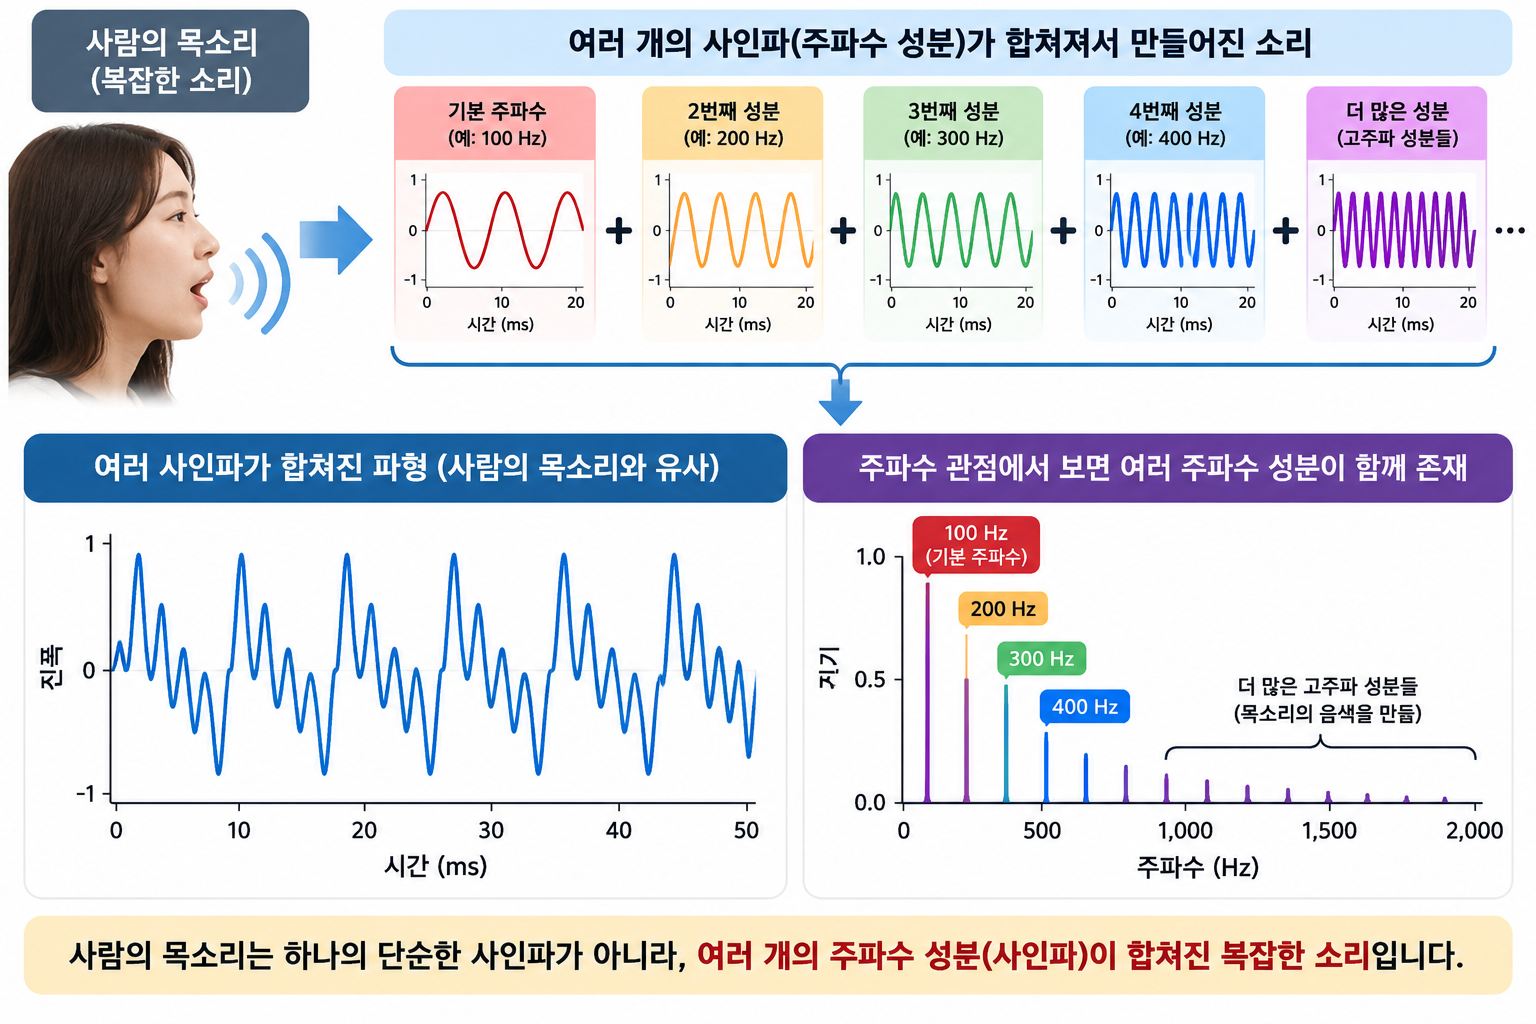
---

---
### FFT 결과는 왜 복소수로 표현 할까요?

**복소수**는 **실수와 허수를 함께 표현하는 수**로, 보통 `a + bi` 형태로 나타냅니다.  
FFT에서는 복소수를 이용해 각 주파수의 **크기(Magnitude)와 위상(Phase)** 정보를 함께 표현합니다.  

음성 파일에 저장된 값은 **실수**입니다.

```text
음성 샘플
0.12, 0.35, -0.21, -0.42, 0.18 ...
```

그런데 FFT로 주파수를 분석할 때는 각 주파수에 대해 두 가지 정보가 필요합니다.

```text
440Hz
 ├─ 얼마나 강한가? → 크기(Magnitude)
 └─ 진동의 위치는? → 위상(Phase)
```

예를 들어 같은 440Hz 소리라도 시작 위치가 다를 수 있습니다.

```text
파형 A :   /‾\_/‾\_/‾\_
파형 B : _/‾\_/‾\_/‾\_
          ↑ 시작 위치가 다름
```

두 파형은 **주파수는 440Hz로 같지만 위상은 다릅니다.**

FFT에서는 이처럼 **크기와 위상이라는 두 가지 정보를 하나의 값으로 표현하기 위해 복소수**를 사용합니다.

```text
FFT 결과(복소수)
      ↓
 ┌────┴────┐
크기       위상
Magnitude  Phase
```

따라서 복소수를 어렵게 생각할 필요는 없습니다.

> **음성 자체에 허수가 들어 있다는 뜻이 아닙니다.**  
> 복소수는 FFT가 각 주파수의 **크기와 위상을 함께 계산하고 표현하기 위해 사용하는 수학적 도구**입니다.

NumPy에서는 다음과 같이 확인할 수 있습니다.

```python
fft_result = np.fft.rfft(audio)   # FFT 결과 → 복소수

magnitude = np.abs(fft_result)    # 크기(Magnitude)
phase = np.angle(fft_result)      # 위상(Phase)
```
np.fft.rfft(audio)    # 실수 음성 신호를 FFT하여 주파수 성분으로 변환  
np.abs(fft_result)    # 각 주파수 성분의 크기(Magnitude)를 계산  
np.angle(fft_result)  # 각 주파수 성분의 위상(Phase)을 계산  

**`복소수 = 주파수의 크기와 위상을 함께 담기 위한 값` 정도로 이해하면 충분!**

---

### FFT — 소리를 주파수별로 나누어 보기

**DFT(Discrete Fourier Transform, 이산 푸리에 변환)** 는 시간에 따라 측정된 디지털 신호를 주파수 성분으로 분해하는 수학적 변환입니다.

예를 들어 440Hz와 880Hz가 섞인 음성을 DFT로 분석하면 두 주파수가 포함되어 있다는 것을 알아낼 수 있습니다.

**FFT(Fast Fourier Transform, 고속 푸리에 변환)** 는 DFT를 빠르게 계산하는 알고리즘입니다. 한 구간의 파형을 분석하여 각 주파수 성분의 **크기(Magnitude)** 와 **위상(Phase)** 을 구합니다.

사인파 하나는 다음 세 정보로 표현할 수 있습니다.

$$
y(t) = A\sin(2\pi f t + \phi)
$$

- **A, Amplitude(앰플리튜드)**: 진폭 — 얼마나 큰가
- **f, Frequency(프리퀀시)**: 주파수 — 얼마나 빠르게 진동하는가
- **φ, Phase(페이즈)**: 위상 — 파형의 기준 위치가 어디인가

FFT 입력인 음성은 **실수**이지만, 각 주파수의 크기와 위상을 함께 계산하고 표현하기 위해 FFT 결과에는 **복소수**가 사용됩니다.  
음성 자체에 허수가 존재한다는 뜻은 아닙니다.  
복소수는 **주파수를 분석하기 위한 수학적 도구**입니다.

```python
fft_result = np.fft.rfft(audio)  # FFT 수행 : 실수로 이루어진 음성 신호 audio를 시간 영역에서 주파수 영역으로 변환
magnitude = np.abs(fft_result)   # 크기 계산 : FFT 결과인 복소수의 절댓값을 계산 - 해당 주파수 성분이 얼마나 강하게 포함되어 있는가?
phase = np.angle(fft_result)     # 위상 계산 : FFT 결과인 복소수의 각도(위상)를 계산 - 해당 주파수의 파형이 어떤 위상 상태에 있는가?
```

### 실수 음성 신호의 FFT와 주파수 간격

#### 1. 왜 `rfft()`를 사용할까요?

음성 데이터는 일반적으로 실수로 이루어진 숫자 배열입니다.

이 데이터를 FFT로 분석하면 양의 주파수와 음의 주파수가 나타납니다.

- **양의 주파수**: 우리가 주로 분석하는 주파수 영역
- **음의 주파수**: 양의 주파수와 대칭 관계에 있는 정보

실수 신호에서는 두 영역의 정보가 서로 대응하므로 모두 계산할 필요가 없습니다.

따라서 **`rfft()`는 중복되는 부분을 생략하고 0Hz부터 나이퀴스트 주파수까지 계산**합니다.

예를 들어 샘플링 레이트가 22,050Hz라면 0~11,025Hz 범위를 분석합니다.

#### 2. FFT의 주파수 간격이란?

FFT는 주파수를 일정한 간격의 칸으로 나누어 결과를 보여줍니다.

주파수 칸 사이의 간격은 다음과 같습니다.

$$
\Delta f = \frac{SR}{N}
$$

- **SR**: 샘플링 레이트
- **N**: FFT에 사용하는 샘플 개수
- **Δf**: 주파수 칸 사이의 간격(Hz)

예를 들어 SR=22,050Hz, N=1,024라면,

$$
\Delta f = \frac{22050}{1024} \approx 21.5Hz
$$

FFT 결과는 다음과 같은 주파수 칸으로 표시됩니다.

**0Hz → 21.5Hz → 43.1Hz → 64.6Hz → ... → 11,025Hz**

즉, 약 21.5Hz 간격으로 주파수 성분을 확인할 수 있습니다.

#### 3. 기억해야 할 핵심

- **`rfft()`**: 실수 신호에서 중복되는 주파수 정보를 생략하여 효율적으로 FFT 계산
- **`SR / N`**: FFT 결과의 주파수 칸 간격
- **N이 커지면**: 주파수 칸 간격이 좁아져 더 세밀하게 주파수를 살펴볼 수 있음

**핵심:** FFT는 소리에 포함된 주파수를 찾아내는 방법이며, `rfft()`는 실수 음성을 효율적으로 분석하는 함수입니다.

---

---

audio  
  │  
  ▼  
np.fft.rfft()  
  │  
  │  복소수 FFT 결과  
  │  
  ├── np.abs()   → Magnitude(크기)  
  │                 주파수 성분이 얼마나 강한가  
  │  
  └── np.angle() → Phase(위상)  
                    주파수 성분의 위상은 어떠한가  

---



---

### FFT는 어떻게 주파수를 찾아낼까요?

FFT는 원래 신호에 **여러 주파수의 기준 파형을 비교**하여  
어떤 주파수가 얼마나 포함되어 있는지 찾아냅니다.

예를 들어 원래 신호에 **440Hz가 포함되어 있는지** 확인한다고 하겠습니다.

```text
원래 신호
   ×
440Hz 기준 파형
   ↓
곱한 값을 모두 더함
```

**440Hz가 포함되어 있다면**

두 파형의 변화가 잘 맞기 때문에 곱한 값이 같은 방향으로 많이 누적되어  
**큰 값**이 만들어집니다.

```text
+ + + + + +  → 큰 값
```

**440Hz가 포함되어 있지 않다면**

두 파형이 잘 맞지 않아 곱한 값의 양수와 음수가 서로 상쇄되어  
**작은 값**이 만들어집니다.

```text
+ - + - + -  → 서로 상쇄 → 작은 값
```

FFT는 이러한 비교를 여러 주파수에 대해 수행합니다.

```text
200Hz 기준 파형 → 작은 값
440Hz 기준 파형 → 큰 값   ← 440Hz 성분이 강함
700Hz 기준 파형 → 작은 값
```

> **주파수가 맞으면 값이 누적되고, 맞지 않으면 양수와 음수가 서로 상쇄됩니다.  
> 이를 이용하여 FFT는 원래 신호에 포함된 주파수와 그 크기를 찾아냅니다.**

※ 실제 FFT에서는 위상까지 찾기 위해 **sin과 cos 성분을 함께 사용**합니다.
```


---

### FFT의 한계 — 어떤 주파수인지는 알지만 ‘언제’인지는 모른다

FFT는 **분석한 구간 전체에 어떤 주파수 성분이 있는지**는 잘 보여 줍니다.  
하지만 전체 음성을 한 번에 FFT하면 각 주파수가 **언제 나타났는지**에 대한 시간 정보는 알기 어렵습니다.  

예를 들어 1초 동안 300 → 600 → 900 → 1500 Hz가 차례로 나온 소리를 전체 FFT하면 네 주파수 성분은 찾을 수 있지만, 그 **발생 순서**는 알 수 없습니다.

```text
전체 Waveform ── FFT ──> 주파수별 크기
                         300 Hz
                         600 Hz
                         900 Hz
                        1500 Hz
                 → 언제 나왔는지는 알기 어려움
```

이 문제를 해결하기 위해 음성을 짧게 나누어 각각 FFT를 수행합니다. 이것이 **STFT**입니다.


### STFT — 짧게 나누어 FFT를 반복하기

**STFT(Short-Time Fourier Transform, 단시간 푸리에 변환)** 는 긴 음성을 짧은 구간(Frame)으로 나누고, 각 구간마다 FFT를 반복하는 방법입니다.

```text
긴 Waveform
   ↓ 짧은 구간으로 나누기
[Frame 1] [Frame 2] [Frame 3] ...
    ↓         ↓         ↓
   FFT       FFT       FFT
    ↓         ↓         ↓
시간별 주파수 정보 → Spectrogram
```

- **Frame / Window**: 한 번에 분석하는 짧은 구간
- **Hop Length**: 다음 구간으로 이동하는 샘플 수
- **Window Function**: 구간 경계에서 생기는 주파수 번짐을 줄이는 함수(Hann 등)
- **Spectrogram(스펙트로그램)**: STFT 결과를 시간×주파수 그림으로 표현한 것

```text
Waveform : 시간에 따라 진폭이 어떻게 변하는가?
FFT      : 어떤 주파수 성분이 들어 있는가?
STFT     : 어떤 주파수 성분이 언제 나타나는가?
```

STFT에서는 분석 구간이 짧을수록 **시간 변화**를 잘 보고,  
길수록 **주파수 차이**를 더 세밀하게 볼 수 있습니다.  
따라서 시간 해상도와 주파수 해상도 사이에는 **Trade-off**가 있습니다.

### 시간 해상도와 주파수 해상도의 Trade-off

**짧게 자르는 경우와 길게 자르는 경우 비교**

```text
짧게 자르는 경우  
┌──┐┌──┐┌──┐┌──┐
FFT FFT FFT FFT

→ 언제 변했는지 잘 보임
→ 주파수 구분은 덜 정밀

길게 자르는 경우  
┌──────────┐┌──────────┐
    FFT          FFT

→ 주파수를 세밀하게 구분
→ 언제 변했는지는 덜 정확


In [1]:
import numpy as np                         # 숫자 배열을 계산하는 도구
import matplotlib.pyplot as plt            # 숫자를 그래프로 보는 도구
from IPython.display import Audio, display # 노트북 안에 재생 버튼을 표시하는 도구
from pathlib import Path                   # 파일 위치를 표현하는 도구
import json                                # 작은 결과 기록을 저장하는 도구
import matplotlib.font_manager as fm

# 그래프에 한글을 표시합니다. 이 준비 코드는 수정하지 않고 실행합니다.
available_fonts = {font.name for font in fm.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 3)
plt.rcParams["figure.dpi"] = 110

SR = 16000  # 이번 기초 실습의 기준: 1초에 16,000개. 모든 모델의 공통 규격이라는 뜻은 아닙니다.
print("준비 완료 / 이번 실습의 SR:", SR)

준비 완료 / 이번 실습의 SR: 16000


**파일 실행 방법:** ZIP을 풀고, 노트북과 `data` 폴더가 함께 있는 폴더에서 Jupyter를 시작합니다.  
2·3강은 같은 예제 WAV를 읽습니다. 예제 파일이 없으면 아래 셀에서 동일한 조건의 합성음을 자동 생성합니다.  
실제 음성에는 2강의 `my_voice.wav`를 `data` 폴더나 노트북과 같은 폴더에 놓으세요.  
각 노트북은 다른 강의의 실행 기록 없이도 실행됩니다.  
한글 글꼴이 없는 환경에서는 그래프 글자가 네모로 보일 수 있습니다.  
제공 HTML에는 검증 환경에서 만든 그래프가 포함되어 있습니다.  

### 제공 도구: 이번 수업의 PCM16 WAV 읽기  

묶음에 들어 있는 WAV는 **16비트 정수 PCM** 형식입니다.  
(참고 : **PCM**(Pulse Code Modulation)은 마이크로 들어온 소리의 크기를 일정한 시간 간격으로 측정하여 숫자로 저장하는 방식)   
이 형식의 숫자 범위는 -32768 ~ 32767입니다.  
계산하기 편하게 실수로 바꾼 뒤 32768로 나누면 -1~1 부근의 값이 됩니다.  
모든 WAV를 무조건 32768로 나누는 것은 아닙니다.  
이 도구는 형식을 확인한 뒤 **PCM16만** 받습니다.  

In [2]:
from scipy.io import wavfile

def read_pcm16(path):
    """PCM16 파일 → (샘플링레이트, 계산용 실수 배열). 채널은 그대로 둡니다."""
    sr, integers = wavfile.read(path)
    if integers.dtype != np.int16:
        raise ValueError("이번 실습에는 16비트 정수 PCM WAV를 사용하세요.")
    if sr <= 0 or integers.size == 0:
        raise ValueError("SR이 올바르고 샘플이 들어 있는 WAV가 필요합니다.")
    if integers.ndim not in (1, 2):
        raise ValueError("모노 또는 채널 축이 있는 WAV가 필요합니다.")
    sound = integers.astype(np.float32) / 32768.0  # 정수 → 실수 → 크기 눈금 변환
    return int(sr), sound

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
sample_path = DATA_DIR / "tone_sequence_16k_mono.wav"
if not sample_path.exists():
    # 2초 예제: 0.20~0.80초 440Hz, 1.00~1.60초 880Hz, 나머지는 무음
    sample_times = np.arange(2 * SR) / SR
    generated = np.zeros(2 * SR, dtype=np.float32)
    for start, end, hz in [(0.20, 0.80, 440), (1.00, 1.60, 880)]:
        mask = (sample_times >= start) & (sample_times < end)
        generated[mask] = 0.35 * np.sin(2 * np.pi * hz * sample_times[mask])
    wavfile.write(sample_path, SR, np.round(generated * 32767).astype(np.int16))
    print("예제 합성음 생성:", sample_path)


In [3]:
sr, audio = read_pcm16(sample_path)
print("공통 파일:", sample_path.name, "/", sr, "Hz /", len(audio) / sr, "초")
display(Audio(audio, rate=sr, normalize=False))

공통 파일: tone_sequence_16k_mono.wav / 16000 Hz / 2.0 초


## 1교시 — 같은 소리에서 ‘어떤 성분이 있는가’를 보기

### 실제 소리와 수업용 사인파

**실제 소리**는 대부분 여러 주파수가 합쳐진 **복잡한 파형**입니다.  
FFT는 이 복잡한 파형을 분석하여 **어떤 주파수들이 얼마나 포함되어 있는지** 찾아냅니다.

```text
실제 소리  
여러 주파수의 합성 → 복잡한 파형 → FFT → 주파수별로 분해  

단, 수업용 440Hz 사인파 → 하나의 주파수 → FFT → 440Hz가 강하게 나타남  
```

여러 재료가 섞인 음식에서 재료의 종류를 살피듯, 소리도 여러 주파수 성분으로 살펴볼 수 있습니다.  
이 비유에서 재료는 **440 Hz 같은 반복 성분**입니다.  
FFT가 ‘사람 목소리’나 ‘피아노’라는 이름을 알아내는 것은 아닙니다.

**DFT**는 숫자 배열을 주파수 관점으로 바꾸는 변환이고, **FFT**는 그 계산을 빠르게 하는 방법입니다.
이번에는 계산 과정을 외우기보다 결과의 가로축과 봉우리를 읽습니다.

### 실습 1 — 전체 파형 다시 보기

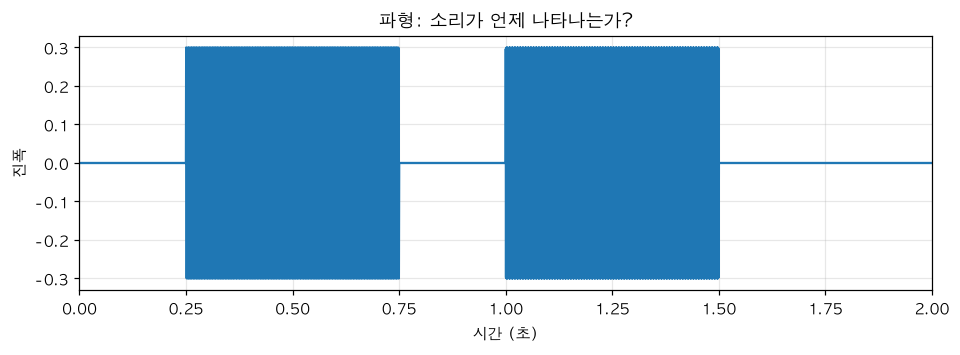

In [4]:
time = np.arange(len(audio)) / sr
plt.figure()
plt.plot(time, audio)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("파형: 소리가 언제 나타나는가?")
plt.xlim(0, 2)
plt.grid(alpha=0.3)
plt.show()

<details>
<summary><b>정답 보기</b></summary>

파란색 영역은 소리가 존재하는 구간입니다.

이 구간의 파형은 실제로는 위아래로 매우 빠르게 진동하고 있습니다.  
하지만 긴 시간 구간을 한 화면에 표시하면 많은 파형이 매우 촘촘하게 겹쳐 보여  
**파란색 사각형처럼 보이게 됩니다.**  

따라서 파란색 영역이 실제로 사각형 모양의 신호라는 의미는 아닙니다.  
해당 구간을 짧게 확대하면 실제 파형의 진동 모습을 확인할 수 있습니다.  


</details>

 - 파란색의 사각형 영역의 의미와 왜 전체가 파랗게 보일까요?

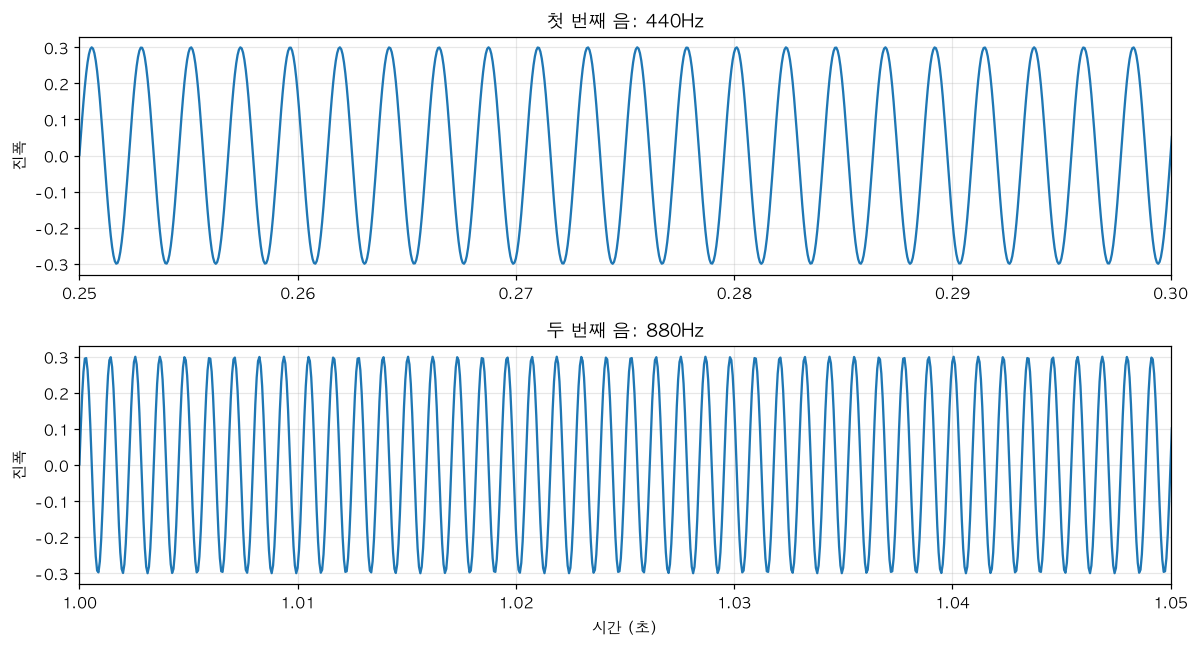

In [5]:
time = np.arange(len(audio)) / sr

# 세로로 2개의 그래프 생성
fig, axes = plt.subplots(2, 1, figsize=(11, 6))

# 위쪽 그래프: 첫 번째 음 (440Hz)
axes[0].plot(time, audio)
axes[0].set_xlim(0.25, 0.30)
axes[0].set_title("첫 번째 음: 440Hz")
axes[0].set_ylabel("진폭")
axes[0].grid(alpha=0.3)

# 아래쪽 그래프: 두 번째 음 (880Hz)
axes[1].plot(time, audio)
axes[1].set_xlim(1.00, 1.05)
axes[1].set_title("두 번째 음: 880Hz")
axes[1].set_xlabel("시간 (초)")
axes[1].set_ylabel("진폭")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**먼저 예상:** 어느 구간에 소리가 있는지는 보입니다. 두 구간 중 어느 쪽이 더 높은 음인지도 이 그림만으로 쉽게 알 수 있나요?

### 실습 2 — 전체 파일의 크기 스펙트럼

아래 세 줄은 ‘변환하기 → 크기만 보기 → Hz 축 붙이기’ 순서입니다.
`rfft`는 실수 파형에 사용할 수 있는 FFT 함수입니다. 내부 계산을 직접 작성할 필요는 없습니다.

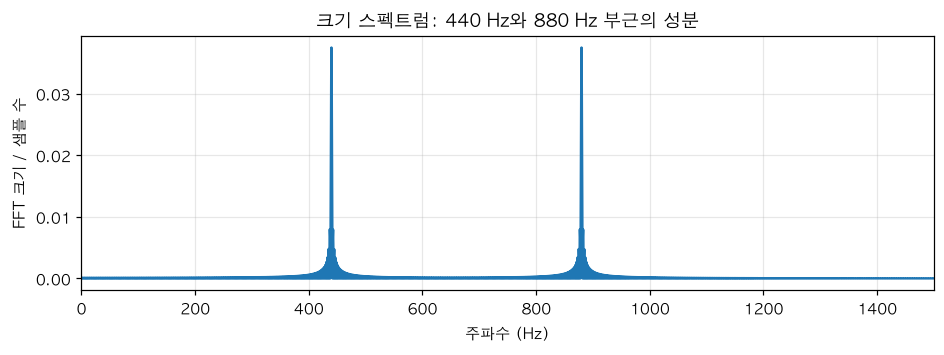

In [6]:
# 시간에 따라 변하는 음성 신호를 분석하여 어떤 주파수가 얼마나 강하게 포함되어 있는지 확인
# 1. 음성 신호를 FFT로 변환
# 시간 영역의 음성 데이터를 주파수 영역으로 변환합니다.
# rfft()는 실수 신호에서 중복되는 음의 주파수 영역을 생략합니다.
fft_result = np.fft.rfft(audio)

# 2. 각 주파수 성분의 크기 계산
# FFT 결과에는 주파수별 크기와 위상 정보가 복소수로 저장되어 있습니다.
# np.abs()는 각 복소수의 크기를 계산하여 주파수별 성분의 강도를 구합니다.
# FFT는 샘플들의 기여를 합산하므로, 샘플 수로 나누어 분석 길이에 따른 영향을 보정합니다.
# 결과는 전체 음성에서 각 주파수 성분이 얼마나 강한지를 나타내며, 전체에 대한 비율(%)은 아닙니다.
fft_size = np.abs(fft_result) / len(audio)


# 3. FFT 결과에 대응하는 주파수 계산
# 각 FFT 결과가 몇 Hz에 해당하는지 구합니다.
# d는 샘플 하나를 측정하는 시간 간격(1 / sr)입니다.
frequency_axis = np.fft.rfftfreq(len(audio), d=1 / sr)

# 4. 주파수별 크기를 그래프로 표시
plt.figure()
plt.plot(frequency_axis, fft_size)

plt.xlabel("주파수 (Hz)")          # X축: 주파수
plt.ylabel("FFT 크기 / 샘플 수")    # Y축: 주파수 성분의 크기
plt.title("크기 스펙트럼: 440 Hz와 880 Hz 부근의 성분")

plt.xlim(0, 1500)                  # 0~1500Hz 범위만 표시
plt.grid(alpha=0.3)                # 그래프에 보조 눈금 표시
plt.show()

**축 읽기:** 가로축은 이제 시간이 아니라 주파수입니다. 봉우리가 있는 주파수 부근의 성분이 강하게 나타납니다.
세로축은 이 코드가 계산한 크기이며, 실제 녹음 공간의 소음계 수치나 원래 사인파 진폭과 바로 같은 숫자는 아닙니다.
관찰 구간과 계산 방식에 따라 값이 달라질 수 있습니다.

**정확히 구분:** 지금은 FFT 결과에서 **크기만** 그렸습니다. FFT 전체에는 위상 정보도 있습니다.
‘FFT가 시간 정보를 모두 없앤다’고 외우지 않습니다. 오늘의 전체 크기 그래프에 시간축이 없어
음의 발생 순서를 직접 읽기 어렵다는 뜻입니다.

### 실습 3 — 한 구간의 주된 봉우리 읽기

In [7]:
# 1. 첫 번째 음이 포함된 0.25~0.75초 구간 추출
# 시간(초)에 샘플링 레이트(sr)를 곱하면 샘플 위치가 됩니다.
first_part = audio[int(0.25 * sr):int(0.75 * sr)]

# 2. 선택한 구간을 FFT로 분석
# rfft(): 주파수 성분 계산
# abs(): 각 주파수 성분의 크기 추출
part_fft = np.abs(np.fft.rfft(first_part))

# 3. FFT 결과의 각 칸에 해당하는 주파수(Hz) 계산
part_hz = np.fft.rfftfreq(len(first_part), d=1 / sr)

# 4. 가장 큰 FFT 크기를 가진 칸 번호 찾기
peak_index = int(np.argmax(part_fft))

# 5. 해당 칸 번호를 실제 주파수(Hz)로 변환하여 출력
print("첫 번째 음의 가장 큰 봉우리:", part_hz[peak_index], "Hz")

첫 번째 음의 가장 큰 봉우리: 440.0 Hz


이 합성음에서는 약 440 Hz를 찾습니다.  
실제 말소리의 가장 큰 봉우리가 항상 음높이 또는 기본 주파수는 아닙니다.  
말소리에는 배음·공명·잡음 등 여러 요소가 함께 있기 때문입니다. 

---
## 작은 data를 활용한 상세 설명
FFT를 더쉽게 원리를 이해하기 위해 작은 data set을 활용한 시연

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# FFT 핵심 코드 3줄 이해하기
# 학습 목표:
# 1. FFT 결과에 어떤 값이 저장되는지 이해한다.
# 2. np.abs()와 len(audio)로 나누는 이유를 이해한다.
# 3. FFT 결과의 각 주파수와 크기가 어떻게 연결되는지 이해한다.
# ============================================================


# ------------------------------------------------------------
# 1. 작은 가상 음성 데이터 만들기
# ------------------------------------------------------------

# 실제 음성은 수만 개의 샘플로 구성되지만,
# FFT의 원리를 이해하기 위해 8개 샘플만 사용합니다.

demo_sr = 8  # 1초에 8개의 샘플을 측정하는 8Hz

# 1초 동안 두 번 진동하는 2Hz 사인파
# 진폭이 0 → 1 → 0 → -1 순서로 반복됩니다.
demo_audio = np.array([0, 1, 0, -1, 0, 1, 0, -1])

print("1. 원본 데이터")
print("샘플링 레이트:", demo_sr, "Hz")
print("전체 샘플 수:", len(demo_audio))
print("전체 길이:", len(demo_audio) / demo_sr, "초")
print("음성 데이터:", demo_audio)

1. 원본 데이터
샘플링 레이트: 8 Hz
전체 샘플 수: 8
전체 길이: 1.0 초
음성 데이터: [ 0  1  0 -1  0  1  0 -1]


In [9]:
# ------------------------------------------------------------
# 2. 첫 번째 핵심 코드: FFT 실행
# ------------------------------------------------------------

# FFT는 전체 음성을 주파수별로 분석합니다.
# 각 주파수 성분의 분석 결과는 복소수로 저장됩니다.
# 복소수에는 해당 주파수의 크기와 위상 정보가 포함됩니다.
# rfft()는 실수 신호의 중복되는 음수 주파수 결과를 생략합니다.

fft_result = np.fft.rfft(demo_audio) # [ 0  1  0 -1  0  1  0 -1]

print("\n2. FFT 복소수 결과")
print(np.round(fft_result, 3))

# 현재 결과는 다음과 같습니다.
# [0+0j, 0+0j, 0-4j, 0+0j, 0+0j]
#
# 원본 데이터는 8개지만 FFT 결과는 5개입니다.
# 이 5개는 각각 0Hz, 1Hz, 2Hz, 3Hz, 4Hz에 해당합니다.
#
# 세 번째 값인 -4j는 2Hz 주파수 성분의 복소수 계수입니다.
# 음성의 진폭이 -4라는 뜻은 아닙니다.
# 복소수의 크기를 구해야 해당 주파수 성분의 강도를 알 수 있습니다.



2. FFT 복소수 결과
[0.+0.j 0.+0.j 0.-4.j 0.+0.j 0.+0.j]


In [10]:
# ------------------------------------------------------------
# 3. 두 번째 핵심 코드: 주파수별 크기 계산
# ------------------------------------------------------------

# FFT 결과는 복소수이므로 np.abs()로 각 복소수의 크기를 계산합니다.
# 전체 음성의 크기 하나를 구하는 것이 아닙니다.
# 주파수마다 하나씩 크기를 계산하여 배열로 반환합니다.

fft_abs = np.abs(fft_result)

print("\n3. 복소수의 크기")
print(np.round(fft_abs, 3))

# 결과: [0, 0, 4, 0, 0]
#
# 2Hz에 해당하는 복소수 -4j의 크기는 4입니다.
# 다른 주파수의 크기는 0에 가깝습니다.
#
# 그런데 이 4는 실제 사인파의 진폭 1과 다릅니다.
# FFT는 여러 샘플의 기여를 합산하므로
# 분석에 사용한 샘플 수가 많아지면 계수의 크기도 커질 수 있습니다.

# 따라서 전체 샘플 수로 나누어 크기를 정규화합니다.
# 이 계산은 전체에 대한 비율(%)을 구하는 것이 아닙니다.
# 또한 결과가 반드시 0~1 사이가 되는 것도 아닙니다.

fft_size = np.abs(fft_result) / len(demo_audio)

print("\n4. 샘플 수로 정규화한 FFT 크기")
print(np.round(fft_size, 3))

# 결과: [0, 0, 0.5, 0, 0]
#
# 2Hz 성분의 크기 = 4 / 8 = 0.5
#
# 여기서 0.5는 전체 음성의 50%라는 의미가 아닙니다.
# 전체 분석 구간에서 2Hz 성분의 크기를
# 샘플 수로 정규화한 결과입니다.
#
# 참고로 진폭 1인 순수 사인파의 해당 주파수 성분은
# 일반적으로 정규화 후 0.5가 됩니다.
# 실제 사인파 진폭을 복원하려면 단측 스펙트럼에서
# DC 및 나이퀴스트 성분을 제외하고 2를 곱해야 합니다.


3. 복소수의 크기
[0. 0. 4. 0. 0.]

4. 샘플 수로 정규화한 FFT 크기
[0.  0.  0.5 0.  0. ]


In [11]:
# ------------------------------------------------------------
# 4. 세 번째 핵심 코드: 주파수 위치 계산
# ------------------------------------------------------------

# 앞에서 구한 fft_size는 각 주파수의 크기 배열입니다.
# 그러나 배열 번호만으로는 실제 주파수가 몇 Hz인지 알기 어렵습니다.
#
# rfftfreq()는 FFT 결과의 각 칸에 해당하는 실제 주파수를 계산합니다.
#
# len(demo_audio) = 8  : 전체 샘플 수
# d = 1 / demo_sr      : 샘플 사이의 시간 간격(초)
#
# 주파수 간격 = 샘플링 레이트 / 샘플 수 = 8 / 8 = 1Hz

frequency_axis = np.fft.rfftfreq(
    len(demo_audio),
    d=1 / demo_sr
)

print("\n5. 주파수 배열")
print(frequency_axis)

# 결과: [0, 1, 2, 3, 4]
#
# frequency_axis[2] = 2.0 : 세 번째 칸은 2Hz
# fft_size[2] = 0.5       : 2Hz 성분의 정규화된 크기는 0.5
#
# 두 배열은 같은 인덱스끼리 연결됩니다.
# frequency_axis → 그래프의 X축 (주파수)
# fft_size       → 그래프의 Y축 (주파수 성분의 크기)


5. 주파수 배열
[0. 1. 2. 3. 4.]


In [12]:
# ------------------------------------------------------------
# 5. FFT 결과 전체 확인
# ------------------------------------------------------------

print("\n6. 주파수별 분석 결과")
print("인덱스 | 주파수(Hz) | FFT 복소수 | 복소수 크기 | 정규화 크기")
print("-" * 65)

for i in range(len(fft_result)):
    print(
        f"{i:^6} | "
        f"{frequency_axis[i]:^10.1f} | "
        f"{fft_result[i]:^12.1f} | "
        f"{fft_abs[i]:^11.2f} | "
        f"{fft_size[i]:^11.2f}"
    )


6. 주파수별 분석 결과
인덱스 | 주파수(Hz) | FFT 복소수 | 복소수 크기 | 정규화 크기
-----------------------------------------------------------------
  0    |    0.0     |   0.0+0.0j   |    0.00     |    0.00    
  1    |    1.0     |   0.0+0.0j   |    0.00     |    0.00    
  2    |    2.0     |   0.0-4.0j   |    4.00     |    0.50    
  3    |    3.0     |   0.0+0.0j   |    0.00     |    0.00    
  4    |    4.0     |   0.0+0.0j   |    0.00     |    0.00    


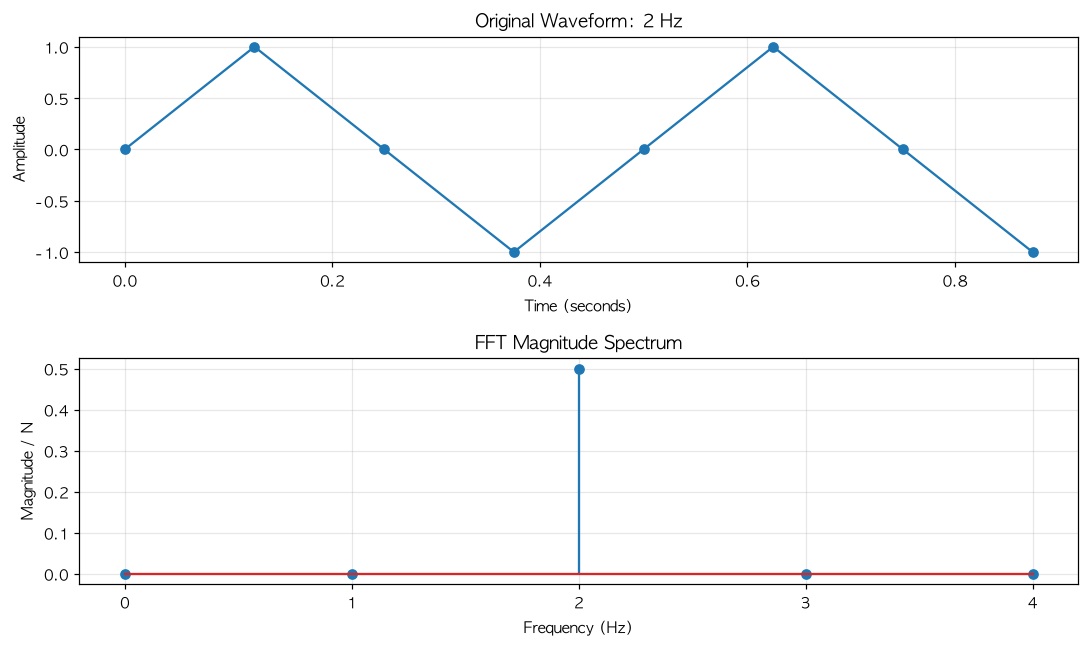

In [13]:
# ------------------------------------------------------------
# 6. 파형과 FFT 결과 비교
# ------------------------------------------------------------

demo_time = np.arange(len(demo_audio)) / demo_sr

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# 위쪽: 시간 영역
# 시간에 따라 진폭이 어떻게 변하는지 확인합니다.
axes[0].plot(demo_time, demo_audio, marker="o")
axes[0].set_title("Original Waveform: 2 Hz")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(alpha=0.3)

# 아래쪽: 주파수 영역
# 어느 주파수 성분이 강하게 포함되어 있는지 확인합니다.
axes[1].stem(frequency_axis, fft_size)
axes[1].set_title("FFT Magnitude Spectrum")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude / N")
axes[1].set_xticks(frequency_axis)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# 7. 추가 확인: 왜 len(audio)로 나누는가?
# ============================================================

# 동일한 2Hz 사인파를 1초와 2초 동안 분석합니다.
# 두 신호의 주파수와 진폭은 같고, 샘플 수만 다릅니다.
# FFT 주파수 간격 = 샘플링 레이트(SR) / 샘플 수(N)
# 1초 음성: 8Hz / 8개 = 1Hz 간격 → 0, 1, 2, 3, 4Hz (5개)
# 2초 음성: 8Hz / 16개 = 0.5Hz 간격 → 0, 0.5, 1, ... 4Hz (9개)
# 같은 2Hz 성분도 1초는 인덱스 2, 2초는 인덱스 4에 저장됩니다.
# FFT 크기는 각각 4와 8이지만, 샘플 수로 나누면 모두 0.5입니다.
# 분석 구간이 길수록 주파수 간격은 작아지지만 시간 변화는 구분하기 어려워집니다.

# 1초 음성: 8개 샘플
time_1s = np.arange(8) / demo_sr #데이터 개수 : 8
audio_1s = np.sin(2 * np.pi * 2 * time_1s) 

# 2초 음성: 16개 샘플
time_2s = np.arange(16) / demo_sr #데이터 개수 : 16
audio_2s = np.sin(2 * np.pi * 2 * time_2s)

print("-"*20)
print(f"1초 음성의 음성 data : {audio_1s}")
print(f"2초 음성의 음성 data : {audio_2s}")
print("-"*20)

# 지수 표기 방지, 소수점 둘째 자리까지 표시
np.set_printoptions(suppress=True, precision=2)
# 각 음성의 FFT 결과
result_1s = np.fft.rfft(audio_1s) #1초 음성의 FFT 복소수 결과 5개
result_2s = np.fft.rfft(audio_2s) #2초 음성의 FFT 복소수 결과 9개

print("-"*20)
print(f"1초 음성의 FFT 결과 : {result_1s}")
print(f"2초 음성의 FFT 결과 : {result_2s}")
print("-"*20)

--------------------
1초 음성의 음성 data : [ 0.0000000e+00  1.0000000e+00  1.2246468e-16 -1.0000000e+00
 -2.4492936e-16  1.0000000e+00  3.6739404e-16 -1.0000000e+00]
2초 음성의 음성 data : [ 0.00000000e+00  1.00000000e+00  1.22464680e-16 -1.00000000e+00
 -2.44929360e-16  1.00000000e+00  3.67394040e-16 -1.00000000e+00
 -4.89858720e-16  1.00000000e+00  6.12323400e-16 -1.00000000e+00
 -7.34788079e-16  1.00000000e+00  8.57252759e-16 -1.00000000e+00]
--------------------
--------------------
1초 음성의 FFT 결과 : [ 0.+0.j  0.+0.j -0.-4.j  0.-0.j  0.+0.j]
2초 음성의 FFT 결과 : [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j -0.-8.j  0.-0.j  0.-0.j  0.-0.j  0.+0.j]
--------------------


### FFT 결과의 주파수 칸 개수

`np.fft.rfft()`는 실수 신호에서 중복되는 음수 주파수 결과를 생략하므로, 결과 개수는 다음과 같습니다.  
**N/2**를 감싸고 있는 기호 ⌊ ⌋는 **바닥 함수(Floor Function)** 라고 합니다.  
수학에서는 소수점 이하를 버리고, 해당 값보다 크지 않은 가장 큰 정수를 구하는 기호입니다.  

$$
\text{FFT 결과 개수} = \left\lfloor \frac{N}{2} \right\rfloor + 1
$$

여기서 `N`은 FFT 분석에 사용한 전체 샘플 수입니다.  
- N / 2 = 4: 마지막 주파수 칸의 인덱스

- +1: 인덱스 0에 해당하는 0Hz 성분까지 포함하여 개수를 계산


- **1초 음성:** 8개 샘플 → 5개 주파수 칸 (0, 1, 2, 3, 4Hz)
- **2초 음성:** 16개 샘플 → 9개 주파수 칸 (0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4Hz)

따라서 같은 **2Hz 성분**이라도 다음과 같이 배열의 위치가 달라집니다.

- 1초 음성: `result_1s[2]`
- 2초 음성: `result_2s[4]`

**핵심 정리:** 샘플링 레이트가 같을 때 분석 샘플 수가 많아지면 FFT의 주파수 간격이 작아져, 더 세밀한 주파수 칸으로 분석할 수 있습니다.

In [15]:
# ============================================================
# 1초와 2초 음성의 FFT 크기 비교
# 목적: 샘플 수가 달라질 때 FFT 크기가 어떻게 달라지는지 확인
# ============================================================

# 1. 각 음성의 FFT 계산
# FFT 결과는 주파수별 크기와 위상 정보를 담은 복소수 배열
result_1s = np.fft.rfft(audio_1s)
result_2s = np.fft.rfft(audio_2s)

# 2. 복소수의 크기 계산
# np.abs()는 각 주파수 성분의 복소수 크기를 계산
size_1s = np.abs(result_1s)
size_2s = np.abs(result_2s)

# 3. FFT 결과에 해당하는 실제 주파수(Hz) 계산
# 1초와 2초 음성은 샘플 수가 다르므로 주파수 간격도 다름
hz_1s = np.fft.rfftfreq(len(audio_1s), d=1 / demo_sr)
hz_2s = np.fft.rfftfreq(len(audio_2s), d=1 / demo_sr)

# 4. 주파수별 FFT 크기 비교
# 복소수 대신 크기만 출력하여 1초와 2초 음성을 비교
print("주파수 | 1초 FFT 크기 | 2초 FFT 크기")
print("-" * 40)

for hz in range(5):
    # 각 음성에서 해당 주파수에 가장 가까운 FFT 칸 찾기
    idx_1s = np.argmin(np.abs(hz_1s - hz))
    idx_2s = np.argmin(np.abs(hz_2s - hz))

    print(f"{hz:4d}Hz | {size_1s[idx_1s]:11.2f} | {size_2s[idx_2s]:11.2f}")

# 5. 2Hz 성분의 정규화 전후 비교
# 같은 2Hz 사인파이지만 2초 음성은 샘플 수가 두 배이므로
# 정규화하지 않은 FFT 크기도 두 배로 나타남
idx_1s = np.argmin(np.abs(hz_1s - 2))
idx_2s = np.argmin(np.abs(hz_2s - 2))

print("\n2Hz 성분의 정규화 전후 비교")
print("-" * 53)
print("구분  | 샘플 수 | 정규화 전 크기 | 정규화 후 크기")
print("-" * 53)

print(f"1초   | {len(audio_1s):7d} | {size_1s[idx_1s]:14.2f} | "
      f"{size_1s[idx_1s] / len(audio_1s):14.2f}")

print(f"2초   | {len(audio_2s):7d} | {size_2s[idx_2s]:14.2f} | "
      f"{size_2s[idx_2s] / len(audio_2s):14.2f}")

# 결과 해석
# - 같은 진폭의 2Hz 사인파이지만 1초 FFT 크기는 4, 2초는 8
# - FFT는 샘플들의 기여를 합산하므로 샘플 수에 따라 크기가 달라짐
# - 각 샘플 수로 나누면 두 경우 모두 0.5
# - 이것이 fft_size = np.abs(fft_result) / len(audio)를 사용하는 이유
# 예상 결과:
#
# 1초 음성 - 샘플 수: 8  / FFT 크기: 4.0
# 2초 음성 - 샘플 수: 16 / FFT 크기: 8.0
#
# 샘플 수로 나눈 결과
# 1초 음성: 0.5
# 2초 음성: 0.5
#
# 같은 진폭의 사인파라도 샘플이 두 배 많아지면
# 이 예제에서는 FFT 계수의 크기도 두 배가 됩니다.
#
# 샘플 수로 나누면 분석 길이에 따른 크기 차이를 보정할 수 있습니다.
#
# ============================================================
# 최종 정리
#
# 1. rfft(audio)
#    전체 음성을 주파수별로 분석하여 복소수 배열을 반환합니다.
#
# 2. np.abs(fft_result) / len(audio)
#    주파수별 복소수 크기를 계산하고 샘플 수로 정규화합니다.
#    이 값은 기여율(%)이나 원본 진폭 자체를 의미하지 않습니다.
#
# 3. rfftfreq(len(audio), d=1/sr)
#    각 FFT 결과가 실제 몇 Hz인지 계산합니다.
#
# FFT는 전체 구간의 주파수 성분을 분석합니다.
# 각 주파수가 언제 나타났는지는 STFT를 통해 분석합니다.
# ============================================================

주파수 | 1초 FFT 크기 | 2초 FFT 크기
----------------------------------------
   0Hz |        0.00 |        0.00
   1Hz |        0.00 |        0.00
   2Hz |        4.00 |        8.00
   3Hz |        0.00 |        0.00
   4Hz |        0.00 |        0.00

2Hz 성분의 정규화 전후 비교
-----------------------------------------------------
구분  | 샘플 수 | 정규화 전 크기 | 정규화 후 크기
-----------------------------------------------------
1초   |       8 |           4.00 |           0.50
2초   |      16 |           8.00 |           0.50


---

 ### 직접 해보기 · 15분

실습 3의 구간을 1.0~1.5초로 바꾸어 두 번째 음을 확인합니다.  
그다음 ‘소리가 언제 시작하는가’와 ‘어떤 주파수가 있는가’ 중 각 그림이 답하는 질문을 적습니다.  

<details><summary>예시 답안</summary>
두 번째 구간의 가장 큰 봉우리는 약 880 Hz입니다. 파형은 시간 위치, 전체 크기 스펙트럼은 주파수 성분을 읽는 데 도움이 됩니다.
</details>


In [16]:
#실습 3 수정한 답안
# 1. 첫 번째 음이 포함된 1.0~1.55초 구간 추출
# 시간(초)에 샘플링 레이트(sr)를 곱하면 샘플 위치가 됩니다.
# first_part = audio[int(0.25 * sr):int(0.75 * sr)]
# --->
first_part = audio[int(1.0 * sr):int(1.55 * sr)]
# 2. 선택한 구간을 FFT로 분석
# rfft(): 주파수 성분 계산
# abs(): 각 주파수 성분의 크기 추출
part_fft = np.abs(np.fft.rfft(first_part))

# 3. FFT 결과의 각 칸에 해당하는 주파수(Hz) 계산
part_hz = np.fft.rfftfreq(len(first_part), d=1 / sr)

# 4. 가장 큰 FFT 크기를 가진 칸 번호 찾기
peak_index = int(np.argmax(part_fft))

# 5. 해당 칸 번호를 실제 주파수(Hz)로 변환하여 출력
print("두 번째 음의 가장 큰 봉우리:", part_hz[peak_index], "Hz")

두 번째 음의 가장 큰 봉우리: 880.0 Hz



## 2교시 — 짧게 나누어 계산하면 시간별 변화가 보인다

긴 동영상을 한 장으로 요약하면 장면 순서를 놓치기 쉽습니다. 대신 짧은 구간마다 살펴보면 무엇이 언제 변했는지 알 수 있습니다.  
**STFT**도 음성을 짧은 구간으로 나누고, 각 구간의 주파수 성분을 계산합니다.

| 용어 | 쉬운 뜻 | 이번 예 |
|---|---|---|
| 프레임 | 한 번에 살펴볼 짧은 소리 조각 | 512샘플 |
| 창 길이 `frame_length` | 한 조각에 담는 샘플 수 | 512 ÷ 16000 = 32ms |
| 이동 간격 `hop_length` | 다음 조각의 시작을 얼마나 옮길지 | 128 ÷ 16000 = 8ms |
| 창 함수 `window` | 조각의 양끝을 부드럽게 줄이는 가중치 | Hann 창을 고정 사용 |



### STFT는 왜 필요할까요?

FFT는 신호에 **어떤 주파수가 포함되어 있는지**는 잘 알려줍니다.  
하지만 긴 음성 전체를 한 번에 FFT하면 **그 주파수가 언제 나타났는지** 알기 어렵습니다.

예를 들어 1초 동안 다음과 같이 소리가 변했다고 하겠습니다.

```text
시간        0초           0.5초           1초
            │─────────────│─────────────│
소리            300Hz          600Hz
```

전체를 한 번에 FFT하면 다음과 같이 알 수 있습니다.

```text
전체 음성 → FFT

300Hz → 있음
600Hz → 있음
```

하지만 이것만으로는 **300Hz와 600Hz가 언제 나타났는지 알 수 없습니다.**

이를 긴 동영상에 비유할 수 있습니다.

> 긴 동영상 전체를 사진 한 장으로 합치면  
> 어떤 장면들이 있었는지는 알 수 있지만  
> **어떤 장면이 언제 나왔는지 알기 어렵습니다.**

그래서 음성을 짧은 구간으로 나눕니다.

```text
전체 음성
│──────│──────│──────│──────│
 구간1   구간2   구간3   구간4
  FFT    FFT    FFT    FFT
```

각 구간마다 FFT를 수행하면

```text
구간1 → 300Hz가 강함
구간2 → 300Hz가 강함
구간3 → 600Hz가 강함
구간4 → 600Hz가 강함
```

처럼 **어떤 주파수가 언제 나타났는지** 알 수 있습니다.

이처럼 음성을 짧은 구간으로 나누고  
**각 구간마다 FFT를 반복해서 수행하는 방법이 STFT**입니다.

> **STFT(Short-Time Fourier Transform)**  
> 음성을 짧은 시간 구간으로 나누어 각각 FFT함으로써  
> **시간에 따라 주파수가 어떻게 변하는지 분석하는 방법**

STFT의 결과를 그림으로 표현한 것이 **Spectrogram(스펙트로그램)** 입니다.

```text
Waveform
   ↓
짧은 구간으로 나누기
   ↓
각 구간마다 FFT
   ↓
STFT
   ↓
Spectrogram
(시간에 따른 주파수 변화)
```
```

### 실습 4 — 숫자 12개로 겹치는 조각 보기

### 학생 실습 A — 두 번째 음의 봉우리 찾기

실습 3을 참고해 **1.0~1.5초** 구간을 선택하고, 해당 구간의 FFT에서 가장 큰 주파수 칸을 출력하세요. 정답 셀은 자신의 코드를 실행한 뒤 확인합니다.

In [17]:
# TODO: 두 번째 음의 구간을 선택하고, rfft와 rfftfreq로 봉우리를 출력하세요.
# second_part = audio[int(... * sr):int(... * sr)]
# print(...)

**내 답:** 첫 음 ___ Hz / 두 번째 음 ___ Hz. 전체 FFT만 보고 두 음의 발생 순서를 알 수 있나요? ___

**정답 및 해설:** `rfftfreq`의 `d=1/sr`는 샘플 하나의 시간 간격입니다. 전체 음성의 길이가 아닙니다.

In [18]:
# 음성 데이터에서 1.0초 ~ 1.5초 구간만 잘라냅니다.
# 시간(초)에 샘플링 레이트(sr)를 곱하면 해당 시간의 샘플 위치를 구할 수 있습니다.
second_part = audio[int(1.0 * sr):int(1.5 * sr)]

# 잘라낸 구간에 FFT를 수행하여 주파수 영역으로 변환합니다.
# rfft() : 실수 음성 신호에서 필요한 양의 주파수 영역만 계산
# abs()  : FFT의 복소수 결과에서 각 주파수의 크기(Magnitude)를 구함
second_size = np.abs(np.fft.rfft(second_part))

# FFT 결과의 각 위치가 실제 몇 Hz에 해당하는지 주파수 값을 만듭니다.
# len(second_part) : FFT에 사용한 샘플 개수
# d=1/sr           : 샘플 하나 사이의 시간 간격
second_hz = np.fft.rfftfreq(len(second_part), d=1 / sr)

# np.argmax(second_size) : Magnitude가 가장 큰 위치(index)를 찾음
# second_hz[index]       : 그 위치에 해당하는 실제 주파수(Hz)를 구함
# 즉, 1.0~1.5초 구간에서 가장 강한 주파수를 출력합니다.
print("두 번째 봉우리:", second_hz[int(np.argmax(second_size))], "Hz")

두 번째 봉우리: 880.0 Hz


In [19]:
# 0부터 11까지의 숫자를 생성합니다.
# 실제 STFT에서는 이 숫자들이 음성의 샘플이라고 생각하면 됩니다.
numbers = np.arange(12)

# 한 번에 가져올 데이터의 개수
# STFT에서는 하나의 Frame 크기에 해당합니다.
frame_length = 6

# 다음 Frame으로 이동할 간격
# 6개를 가져온 후 3칸만 이동하므로 앞 Frame과 데이터가 겹칩니다.
hop_length = 3

# start는 각 Frame의 시작 위치입니다.
# 0 → 3 → 6 순서로 이동합니다.
for start in range(0, len(numbers) - frame_length + 1, hop_length):

    # 시작 위치부터 6개의 데이터를 잘라서 출력합니다.
    print("시작", start, "→ 조각", numbers[start:start + frame_length])

시작 0 → 조각 [0 1 2 3 4 5]
시작 3 → 조각 [3 4 5 6 7 8]
시작 6 → 조각 [ 6  7  8  9 10 11]


0 ~ 5, 3 ~ 8, 6 ~ 11이 출력됩니다. 같은 숫자가 이웃 조각에 다시 들어갑니다.
겹쳐 본다고 원래 소리를 두 번 재생하거나 음성 길이가 늘어나는 것은 아닙니다.

### 제공 도구 — STFT 계산하기

반환값은 **주파수축, 시간축, 주파수별 계산 결과** 세 가지입니다.
이 수업에서는 FFT 길이를 창 길이와 같게 두고, 신호 밖으로 0을 붙이지 않고 완전히 들어오는 조각만 계산합니다.
그래서 첫 시간은 첫 프레임의 중심이고, 끝의 짧은 나머지는 제외될 수 있습니다.

In [20]:
from scipy.signal import stft

def compute_stft(sound, sr, frame_length=512, hop_length=128):
    """
    음성 신호를 짧은 구간으로 나누어 STFT를 수행합니다.
    반환하는 spectrum의 축은 (주파수, 시간)입니다.
    """

    # 창 길이와 이동 간격이 올바른지 확인
    if not (1 <= hop_length <= frame_length <= len(sound)):
        raise ValueError("1 ≤ 이동 간격 ≤ 창 길이 ≤ 샘플 수가 되도록 설정하세요.")

    frequencies, times, spectrum = stft(
        sound,
        fs=sr,                            # 샘플링 레이트(Hz)
        window="hann",                    # 구간 양 끝을 부드럽게 줄이는 창 함수
        nperseg=frame_length,             # FFT로 분석할 한 구간의 샘플 개수
        noverlap=frame_length-hop_length,  # 이웃 구간과 겹치는 샘플 개수
        nfft=frame_length,                # FFT 계산에 사용할 샘플 개수
        boundary=None,                    # 신호 앞뒤에 샘플을 추가하지 않음
        padded=False,                     # 마지막 구간을 채우기 위한 패딩 없음
        detrend=False,                    # 구간별 평균이나 추세를 제거하지 않음
        scaling="spectrum"                # 스펙트럼 크기 기준으로 계산
    )

    return frequencies, times, spectrum

여러 설정은 계산 조건을 명시하기 위한 것입니다. 학생이 직접 바꿀 값은 **창 길이와 이동 간격 두 개**입니다.
한 번에는 그중 하나만 바꿉니다.

### 실습 5 — 가로 시간·세로 주파수·색 크기  
이 코드는 앞에서 만든 compute_stft() 함수를 이용하여 STFT 분석 결과를 스펙트로그램(Spectrogram)으로 시각화하는 실습입니다. 

FFT 그래프는 어떤 주파수가 포함되어 있는지 보여주지만, 스펙트로그램은 어떤 주파수가 언제 나타나는지 색상으로 보여줍니다.

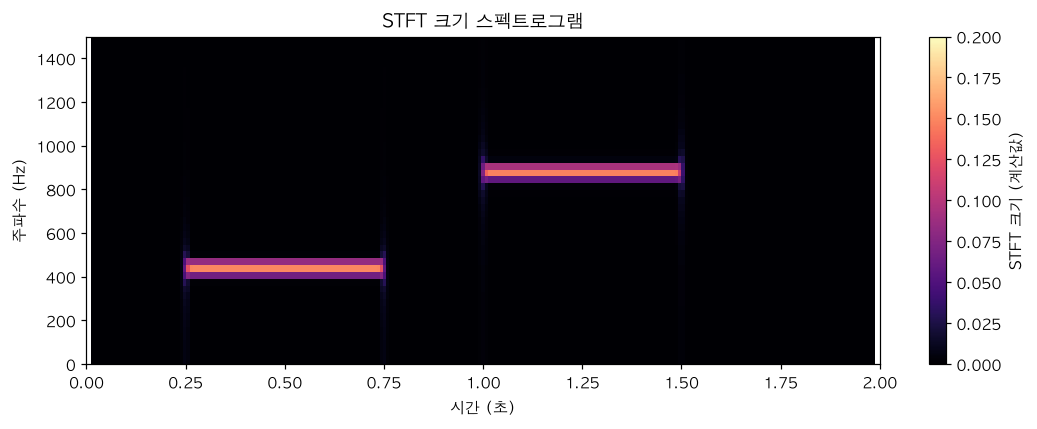

숫자 표의 모양: (257, 247)


In [21]:
# 1. STFT 분석 수행
# frequencies: 주파수 위치(Hz)
# frame_times: 각 분석 구간의 중심 시간(초)
# spectrum: 시간별·주파수별 FFT 결과(복소수)
frequencies, frame_times, spectrum = compute_stft(audio, sr)

# 2. 복소수 결과에서 크기(Magnitude)만 추출
# 크기가 클수록 해당 시간에 해당 주파수 성분이 강함
magnitude = np.abs(spectrum)

# 3. 스펙트로그램을 표시할 그래프 생성
fig, ax = plt.subplots(figsize=(10, 4))

# 4. 시간(X축), 주파수(Y축), 크기(색상)를 이용하여 시각화
mesh = ax.pcolormesh(
    frame_times, frequencies, magnitude,
    shading="auto",    # 색상 격자의 경계를 자동 처리
    cmap="magma",      # 어두운 색 → 밝은 색으로 크기 표현
    vmin=0,            # 색상으로 표시할 최솟값
    vmax=0.2           # 색상으로 표시할 최댓값
)

# 5. 그래프 제목과 축 설정
ax.set(
    xlabel="시간 (초)",
    ylabel="주파수 (Hz)",
    title="STFT 크기 스펙트로그램"
)

ax.set_xlim(0, len(audio) / sr)  # 전체 음성 시간 표시
ax.set_ylim(0, 1500)             # 0~1500Hz 주파수 범위만 표시

# 6. 색상이 나타내는 크기를 확인할 수 있도록 색상 막대 추가
fig.colorbar(mesh, ax=ax, label="STFT 크기 (계산값)")

plt.tight_layout()
plt.show()

# 7. STFT 결과의 배열 크기 확인
print("숫자 표의 모양:", magnitude.shape)

스펙트로그램은 시간별 크기나 파워를 색으로 나타낸 그림입니다. **이번 그림은 크기**를 사용합니다.
밝은 부분은 해당 시간·주파수 칸의 크기가 크다는 뜻입니다. 색은 주파수의 높낮이를 나타내지 않습니다.
또 파일을 그림으로 저장하는 것과 이 숫자 행렬을 모델에 넣는 것은 다릅니다.

### 직접 읽기 · 15분

그림에서 손가락으로 위치를 짚으며 답합니다.

1. 0.5초에는 어느 주파수 부근이 밝은가요?
2. 1.2초에는 어느 주파수 부근이 밝은가요?
3. 소리가 없는 구간은 어떻게 보이나요?
4. 밝은 띠의 시작과 끝이 완벽하게 수직선으로 끊기지 않는 이유는 무엇일까요?

<details><summary>예시 답안</summary>
0.5초는 약 440 Hz, 1.2초는 약 880 Hz입니다. 조용한 구간은 어둡습니다.
경계에 걸친 프레임에는 소리와 무음이 함께 들어 있으므로 시작·끝 주변의 색이 점진적으로 달라질 수 있습니다.
</details>

## 3교시 — 창 길이와 이동 간격은 다른 설정이다

**창 길이**는 한 번에 보는 시간의 폭입니다. **이동 간격**은 다음 관찰 위치로 옮기는 거리입니다.
사진의 노출 시간과 촬영 간격을 따로 생각하는 것과 비슷합니다.

### 실습 6 — 창 길이만 바꾸기

이동 간격은 128로 고정하고, 창 길이만 256·512·1024로 바꿉니다.
비교할 때 색 기준도 모두 같은 0~0.2로 유지합니다.

### 학생 실습 B — 시간별로 주파수 읽기

`frame_times`에서 **0.5초와 1.2초**에 가장 가까운 열을 고르고, `magnitude[:, 열번호]`에서 가장 큰 주파수 칸을 찾아 출력하세요. 무음에서 최대 칸을 음높이로 해석해도 될까요?

In [22]:
# TODO: np.argmin(np.abs(frame_times - target_time))으로 열을 고르세요.
# 두 시각에 대해 frequencies[np.argmax(magnitude[:, 열번호])]를 출력하세요.

**내 답:** 0.5초 ___ Hz / 1.2초 ___ Hz. 무음의 최대 칸이 음높이가 아닌 이유: ___

**정답 코드 및 해설:** 가로 위치는 시간, 세로 위치는 주파수, 색은 크기입니다. 무음의 작은 오차나 0 중 어느 칸이 최대인지는 의미 있는 음높이 추정이 아닙니다.

In [23]:
# STFT 분석 결과에서 특정 시간(0.5초, 1.2초)에 가장 강하게 나타나는 주파수를 찾아 출력하는 실습
# 0.5초와 1.2초에서 가장 강한 주파수를 확인
for target_time in [0.5, 1.2]:

    # STFT 시간 배열에서 목표 시간과 가장 가까운 위치 찾기
    # STFT는 모든 순간을 분석하는 것이 아니라 일정한 간격으로 이동하면서 분석(정확히 0.5초에 해당하는 분석 구간이 없을 수도 있음)
    # frame_times - target_time: 목표 시간과 각 분석 시간의 차이
    # np.abs(...): 차이를 양수로 변환
    # np.argmin(...): 차이가 가장 작은 위치 찾기 
    # 즉, 0.5초와 가장 가까운 STFT 분석 구간을 선택
    column = int(np.argmin(np.abs(frame_times - target_time)))

    # 해당 시간의 모든 주파수 성분 크기 추출
    # 복소수 결과에서 크기(Magnitude)
    band = magnitude[:, column]

    # 가장 큰 크기를 가진 주파수 칸을 찾아 Hz로 출력
    print(f"{target_time}초: {frequencies[int(np.argmax(band))]:.1f} Hz / 크기: {band.max():.4f}")

0.5초: 437.5 Hz / 크기: 0.1494
1.2초: 875.0 Hz / 크기: 0.1475


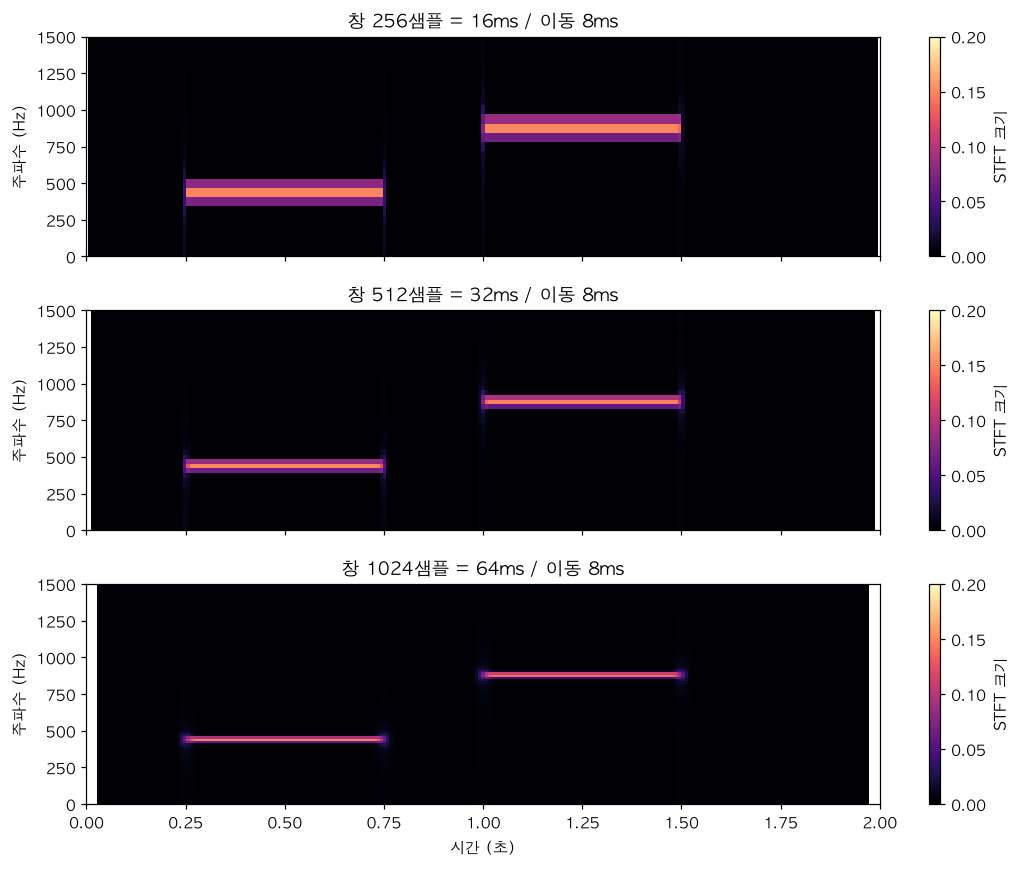

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, frame_length in zip(axes, [256, 512, 1024]):
    f, t, z = compute_stft(audio, sr, frame_length=frame_length, hop_length=128)
    mesh = ax.pcolormesh(t, f, np.abs(z), shading="auto", cmap="magma", vmin=0, vmax=0.2)
    ax.set_title(f"창 {frame_length}샘플 = {frame_length/sr*1000:.0f}ms / 이동 8ms")
    ax.set_ylabel("주파수 (Hz)")
    ax.set_ylim(0, 1500)
    ax.set_xlim(0, 2)
    fig.colorbar(mesh, ax=ax, label="STFT 크기")
axes[-1].set_xlabel("시간 (초)")
plt.tight_layout()
plt.show()

---
## STFT 창 길이에 따른 분석 결과 비교

### 1. 실습 목적

STFT는 음성을 짧은 구간(창)으로 나누어 FFT를 반복하는 방법입니다.

이번 실습에서는 창 길이를 **256, 512, 1024샘플**로 변경하여 스펙트로그램을 비교합니다.

창 길이가 달라지면 다음 두 가지 특성이 달라집니다.

- **시간 해상도**: 소리가 언제 시작하고 끝나는지 구분하는 능력
- **주파수 해상도**: 서로 가까운 주파수 성분을 구분하는 능력

### 2. 창 길이에 따른 설정 비교

샘플링 레이트가 16,000Hz인 경우입니다.

| 구분 | 256샘플 | 512샘플 | 1024샘플 |
|---|---:|---:|---:|
| 창 길이 | 16ms | 32ms | 64ms |
| 주파수 칸 간격 | 62.5Hz | 31.25Hz | 15.625Hz |
| 이동 간격 | 8ms | 8ms | 8ms |
| 시간 변화 구분 | 상대적으로 유리 | 중간 | 상대적으로 불리 |
| 주파수 구분 | 상대적으로 불리 | 중간 | 상대적으로 유리 |

세 가지 설정 모두 이동 간격(Hop Length)은 128샘플, 즉 8ms로 동일합니다.

### 3. 그래프 결과 해석

#### ① 창 길이 256샘플 (16ms)

- 짧은 시간 구간을 분석하므로 소리가 시작하고 끝나는 시점을 비교적 선명하게 확인할 수 있습니다.
- 주파수 칸 간격이 62.5Hz로 넓어 주파수 성분이 상대적으로 퍼져 보일 수 있습니다.
- 시간에 따른 빠른 변화를 관찰하는 데 유리합니다.

#### ② 창 길이 512샘플 (32ms)

- 256샘플보다 주파수 성분을 더 세밀하게 분석할 수 있습니다.
- 시간 변화와 주파수 구분 사이에서 균형을 이루는 설정입니다.
- 시간과 주파수 정보를 함께 관찰하기에 적절합니다.

#### ③ 창 길이 1024샘플 (64ms)

- 긴 시간 구간을 분석하므로 주파수 성분을 더 세밀하게 구분할 수 있습니다.
- 주파수 방향으로 수평선이 상대적으로 좁고 선명하게 나타날 수 있습니다.
- 반면 소리의 시작과 종료 시점은 더 넓은 시간 범위에 걸쳐 나타날 수 있습니다.

### 4. 그래프에서 확인할 사항

**① 주파수 방향의 선 두께**

440Hz와 880Hz 부근의 수평선을 비교합니다.

- 창이 짧을 때: 주파수 방향으로 상대적으로 넓게 나타남
- 창이 길 때: 주파수 방향으로 상대적으로 좁게 나타남

**② 시간 방향의 경계**

440Hz와 880Hz 소리가 시작하고 끝나는 위치를 비교합니다.

- 창이 짧을 때: 시작과 종료 시점이 비교적 선명함
- 창이 길 때: 시작과 종료 시점이 상대적으로 부드럽게 퍼짐

### 5. 핵심 정리

### STFT 창 길이와 해상도의 관계

STFT는 음성을 짧은 구간(창)으로 나누어 FFT를 수행합니다.
이때 **창 길이에 따라 시간 해상도와 주파수 해상도가 달라집니다.**

- **짧은 창**: 소리가 언제 시작하거나 변하는지 구분하기 쉽지만, 가까운 주파수를 구분하기는 어렵습니다.
- **긴 창**: 가까운 주파수를 더 정확하게 구분할 수 있지만, 소리가 언제 변했는지 파악하기는 상대적으로 어렵습니다.

이처럼 한쪽의 해상도를 높이면 다른 쪽의 해상도가 낮아지는 관계를
**시간 해상도와 주파수 해상도의 절충(Trade-off)**이라고 합니다.

따라서 음성 분석에서는 분석 목적에 맞게 적절한 창 길이를 선택해야 합니다.

> **참고: 창 길이와 이동 간격의 차이**
>
> - **창 길이(Frame Length)**: 한 번의 FFT에서 분석하는 신호의 길이로, 시간·주파수 해상도에 영향을 줍니다.
> - **이동 간격(Hop Length)**: 다음 FFT 분석을 위해 창을 이동하는 간격으로, 분석 결과가 시간축에 얼마나 촘촘하게 나타나는지를 결정합니다.
>
> 이동 간격이 같더라도 창 길이가 다르면 시간·주파수 해상도는 달라집니다.
---

**관찰의 초점:** 긴 창에서는 일정한 음의 주파수 띠가 더 좁아지는 경향을 볼 수 있습니다.
대신 시작·끝 부근을 더 긴 시간 동안 함께 보므로 빠른 변화를 시간상 구분하는 데 불리할 수 있습니다.
‘길수록 무조건 좋다’고 정하지 않습니다. 실제 구별 정도는 창 모양·잡음·성분 크기에도 영향을 받습니다.

### 실습 7 — 이동 간격만 바꾸기

In [25]:
for hop_length in [64, 128, 256]:
    f, t, z = compute_stft(audio, sr, frame_length=512, hop_length=hop_length)
    print("창: 32ms / 이동:", hop_length / sr * 1000, "ms",
          "/ 시간 칸 수:", z.shape[1],
          "/ 원래 음성 길이:", len(audio) / sr, "초")

창: 32ms / 이동: 4.0 ms / 시간 칸 수: 493 / 원래 음성 길이: 2.0 초
창: 32ms / 이동: 8.0 ms / 시간 칸 수: 247 / 원래 음성 길이: 2.0 초
창: 32ms / 이동: 16.0 ms / 시간 칸 수: 124 / 원래 음성 길이: 2.0 초


이동 간격이 작으면 더 자주 관찰하므로 시간 칸이 늘어납니다.
**원래 소리 길이나 한 프레임이 보는 32ms가 늘거나 줄지는 않습니다.**
촘촘한 시간 칸과 짧은 창에 의한 빠른 변화 구분은 같은 개념이 아닙니다.

### 직접 비교하기 · 15분

아래에서 먼저 `my_hop`만 256으로 바꾸고 실행합니다. 다시 128로 돌린 뒤 `my_frame`만 1024로 바꿉니다.
달라지는 숫자와 그대로인 숫자를 나누어 기록합니다.

In [26]:
my_frame = 512   # 창 길이: 먼저 고정
my_hop = 128     # 이동 간격: 먼저 이것만 변경
my_f, my_t, my_z = compute_stft(audio, sr, my_frame, my_hop)
print("창이 보는 시간:", my_frame / sr * 1000, "ms")
print("다음 위치로 이동:", my_hop / sr * 1000, "ms")
print("숫자 표 모양:", my_z.shape)
print("음성 길이:", len(audio) / sr, "초")

창이 보는 시간: 32.0 ms
다음 위치로 이동: 8.0 ms
숫자 표 모양: (257, 247)
음성 길이: 2.0 초


| 실험 | 바꾼 값 | 바뀐 결과 | 그대로인 것 |
|---|---|---|---|
| 이동 간격 변경 | | | |
| 창 길이 변경 | | | |

<details><summary>관찰 예시</summary>
이동 간격만 늘리면 시간 칸 수가 줄고 창 길이와 주파수 칸 수는 같습니다.
이번 코드에서는 창 길이와 FFT 길이를 같이 두므로 창을 늘리면 주파수 칸 수도 늘고 관찰 시간 폭도 늘어납니다.
어느 경우에도 입력 음성의 길이는 2초입니다.
### 실습 결과 정리

이번 실습에서는 STFT의 **이동 간격과 창 길이를 각각 변경**하고 결과를 비교했습니다.

| 실험 | 바꾼 값 | 바뀐 결과 | 그대로인 것 |
|---|---|---|---|
| 이동 간격 변경 | 128 → 256 | 이동 시간 8 → 16ms, 시간 구간 247 → 123개 | 창 길이 32ms, 주파수 칸 257개, 음성 길이 2초 |
| 창 길이 변경 | 512 → 1024 | 창 시간 32 → 64ms, 주파수 칸 257 → 513개, 시간 구간 247 → 243개 | 이동 시간 8ms, 음성 길이 2초 |

#### 1. 이동 간격을 변경하면?

이동 간격은 **STFT가 다음 구간을 분석하기 위해 이동하는 거리**입니다.

- 이동 간격이 짧으면 분석 결과가 시간축에 촘촘하게 나타납니다.
- 이동 간격이 길면 분석 횟수가 줄어들고 시간축의 결과가 성기게 나타납니다.
- 창 길이가 같다면 주파수 칸 개수와 주파수 칸 간격은 변하지 않습니다.

#### 2. 창 길이를 변경하면?

창 길이는 **한 번의 FFT에서 분석하는 음성의 길이**입니다.

- 창이 길어지면 더 긴 시간의 신호를 분석합니다.
- 주파수 칸 간격이 작아져 가까운 주파수를 구분하는 데 유리해집니다.
- 대신 소리가 언제 변했는지 구분하는 능력은 상대적으로 낮아집니다.

#### 핵심 정리

- **이동 간격(Hop Length)**: 분석 결과가 시간축에 얼마나 촘촘하게 나타나는지 결정합니다.
- **창 길이(Frame Length)**: 한 번에 분석하는 신호의 길이로, 시간·주파수 해상도에 영향을 줍니다.

따라서 STFT에서는 분석 목적에 맞게 창 길이와 이동 간격을 함께 설정해야 합니다.

> **주의:** 이동 간격을 줄여 시간 구간을 더 많이 계산한다고 해서 실제 시간 해상도가 무조건 높아지는 것은 아닙니다. 시간 해상도는 주로 창 길이의 영향을 받습니다.
</details>



## 4교시 — STFT 분석 결과를 숫자 데이터로 이해하기

앞에서는 STFT를 이용해 음성의 주파수 변화를 스펙트로그램으로 확인했습니다.

스펙트로그램은 단순한 그림이 아니라, **시간별·주파수별 분석 결과를 숫자로 저장한 2차원 배열**을 색상으로 표현한 것입니다.

### 1. 파형 데이터와 STFT 데이터의 차이

| 구분 | 파형(Waveform) | STFT 크기 데이터 |
|---|---|---|
| 데이터 형태 | 1차원 배열 | 2차원 배열 |
| 배열 모양 | `(샘플 수,)` | `(주파수 칸 수, 시간 칸 수)` |
| 저장된 값 | 시간에 따른 진폭 | 시간별·주파수별 성분의 크기 |
| 알 수 있는 정보 | 소리의 진폭 변화 | 주파수 성분의 시간에 따른 변화 |

### 2. STFT 결과는 어떻게 구성될까요?

STFT 결과는 행과 열로 구성된 숫자 표입니다.

- **행(Row)**: 주파수 칸을 나타냅니다.
- **열(Column)**: 분석한 시간 구간을 나타냅니다.
- **각 값**: 해당 시간에 해당 주파수 성분이 얼마나 강한지를 나타냅니다.

예를 들어 특정 시간에 해당하는 열 하나를 선택하면, 그 시간 구간에 포함된 여러 주파수의 크기를 한꺼번에 확인할 수 있습니다.

이러한 숫자 묶음을 **특징 벡터(Feature Vector)** 라고 합니다.

특징 벡터는 해당 시간 구간의 음성 특성을 나타내며, 음성 인식 모델의 입력 데이터를 구성하는 기초가 됩니다.

### 실습 8 — 특정 시간의 주파수 데이터 확인하기

**실습 목적**

STFT 결과에서 특정 시간에 해당하는 숫자 데이터를 추출하고, 그 데이터가 어떤 의미를 갖는지 확인합니다.

**확인할 내용**

1. STFT 결과가 2차원 배열인지 확인합니다.
2. 특정 시간에 해당하는 열 하나를 선택합니다.
3. 선택한 열에 포함된 주파수별 크기를 확인합니다.
4. 가장 강하게 나타나는 주파수를 찾아봅니다.

> **핵심 정리:** 스펙트로그램은 STFT 분석 결과를 색상으로 표현한 그림입니다. 음성 AI 모델은 이 그림 자체가 아니라, 그림을 구성하는 숫자 배열 또는 이를 추가로 변환한 특징 데이터를 입력으로 사용할 수 있습니다.

### 학생 실습 C — 설정을 하나씩 바꾼 결과 기록

기준 `(창 512, 이동 128)`과 실험 ① `(512, 256)`, ② `(1024, 128)`을 실행하세요. 창·이동을 ms로 환산하고 STFT 행렬 모양을 출력한 뒤 위 표를 **자신의 결과**로 채웁니다.

In [27]:
# TODO: 세 설정을 순회하며 compute_stft(audio, sr, frame, hop)를 실행하세요.
# 창 ms, 이동 ms, z.shape, 원본 길이를 출력하세요.

**내 결과:** 기준 ___ / 실험 ① ___ / 실험 ② ___ . 세 경우 모두 원본 길이는 ___초.

**정답 코드:** 주파수 칸 수는 `nfft=창 길이`이므로 창 길이에 따라 변합니다. 이동만 바꾸면 주파수 칸 수는 그대로입니다.

In [28]:
for frame, hop in [(512, 128), (512, 256), (1024, 128)]:
    f, t, z = compute_stft(audio, sr, frame, hop)
    print(f"창 {frame/sr*1000:.0f}ms / 이동 {hop/sr*1000:.0f}ms / 표 {z.shape} / 원본 {len(audio)/sr:.2f}초")

창 32ms / 이동 8ms / 표 (257, 247) / 원본 2.00초
창 32ms / 이동 16ms / 표 (257, 124) / 원본 2.00초
창 64ms / 이동 8ms / 표 (513, 243) / 원본 2.00초


In [29]:
frequencies, frame_times, spectrum = compute_stft(audio, sr, 512, 128)
magnitude = np.abs(spectrum)
selected_column = int(np.argmin(np.abs(frame_times - 0.5))) # 0.5초에 가장 가까운 시간 칸
one_frame = magnitude[:, selected_column]                 # 모든 주파수 행, 선택한 열 하나

print("전체 모양 (주파수, 시간):", magnitude.shape)
print("선택한 프레임 중심:", round(float(frame_times[selected_column]), 3), "초")
print("선택한 열 하나의 모양:", one_frame.shape)
print("가장 큰 칸의 주파수:", frequencies[int(np.argmax(one_frame))], "Hz")

전체 모양 (주파수, 시간): (257, 247)
선택한 프레임 중심: 0.496 초
선택한 열 하나의 모양: (257,)
가장 큰 칸의 주파수: 437.5 Hz


마지막 값은 440과 조금 다를 수 있습니다. 창 길이에 따라 미리 정해진 주파수 칸에서 읽기 때문입니다.
512샘플 창이면 칸 간격이 16000÷512=31.25 Hz여서 440 Hz 근처의 칸이 크게 나타납니다.
공식 암기보다 “칸이 있는 표를 읽고 있다”는 점을 기억하세요.

---

### 실습 9 — STFT 결과를 시간 순서의 특징으로 이해하기

이 실습의 목적은 **STFT 결과를 그림으로 보는 것에서 끝내지 않고, AI 모델에서 사용할 수 있는 시간 순서의 특징과 연결하여 이해하는 것**입니다.

STFT의 크기(Magnitude)는 다음과 같은 형태로 생각할 수 있습니다.

```text
magnitude : (주파수, 시간)

          시간1   시간2   시간3  ...
주파수1     값      값      값
주파수2     값      값      값
주파수3     값      값      값
  ...
```

즉, 각 시간 구간마다 **어떤 주파수가 얼마나 강한지**에 대한 정보가 들어 있습니다.

---

#### 시간 순서로 데이터를 바라보기

LSTM이나 Transformer와 같이 순서를 처리하는 모델을 이해할 때는 데이터를 다음과 같이 **시간 순서**로 생각하는 것이 편합니다.

```text
시간1 → [주파수 특징들]
시간2 → [주파수 특징들]
시간3 → [주파수 특징들]
 ...
```

그래서 다음과 같이 배열을 전치합니다.

```python
sequence_features = magnitude.T
```

`.T`는 행과 열의 위치를 바꾸는 기능입니다.

```text
변환 전 : (주파수, 시간)
              ↓ .T
변환 후 : (시간, 주파수 특징)
```

배열을 전치했다고 해서 **새로운 소리를 만들거나 주파수를 변경한 것은 아닙니다.**  
같은 데이터를 모델이 시간 순서로 보기 편하도록 배열의 방향만 바꾼 것입니다.

---

#### 예를 들어

전치한 배열의 크기가 `(100, 513)`이라고 가정하면 다음과 같이 이해할 수 있습니다.

```text
100 → 시간 구간(Frame)이 100개
513 → 각 시간 구간의 주파수 특징이 513개

시간 1   → [513개의 주파수 특징]
시간 2   → [513개의 주파수 특징]
시간 3   → [513개의 주파수 특징]
 ...
시간 100 → [513개의 주파수 특징]
```

이렇게 하면 음성이 시간에 따라 어떻게 변하는지를 **시간 순서의 특징 데이터**로 표현할 수 있습니다.

> **STFT는 음성을 시간별 주파수 특징으로 바꾸고, 이를 시간 순서로 배열하면 음성의 변화를 순서대로 처리하는 모델의 입력 특징으로 연결할 수 있습니다.**

단, `magnitude.T`를 모든 LSTM이나 Transformer에 그대로 입력한다는 의미는 아닙니다.  
다음 강의에서는 STFT의 주파수 특징을 **Mel 특징**으로 변환하며, 실제 모델에 따라 입력 특징의 종류와 배열 형태는 달라질 수 있습니다.

```text
파형
 ↓
STFT
 ↓
시간별 주파수 특징
 ↓
Mel 특징 등으로 변환
 ↓
모델이 요구하는 입력 형태로 구성
 ↓
음성 모델
```

In [30]:
sequence_features = magnitude.T          # .T는 행과 열의 위치를 바꿈
print("분석용 (주파수, 시간):", magnitude.shape)
print("시간 순서로 읽는 예 (시간, 특징):", sequence_features.shape)
print("첫 시간의 특징 개수:", sequence_features[0].size)

분석용 (주파수, 시간): (257, 247)
시간 순서로 읽는 예 (시간, 특징): (247, 257)
첫 시간의 특징 개수: 257


배열을 전치해도 새 소리를 만들거나 주파수를 변경한 것이 아닙니다. 같은 숫자 표의 축을 바꾼 것입니다.
LSTM·Transformer에서 본 ‘시간마다 입력 벡터를 읽는다’와 연결할 수 있습니다.
실제 모델마다 요구하는 축과 특징이 다르므로 이 표를 모든 모델에 그대로 넣지는 않습니다.

```text
파형 (샘플,)
   ↓ STFT의 크기를 관찰
시간별 주파수 표 (주파수, 시간)
   ↓ 다음 강의: 주파수 칸을 가중합해 Mel 특징 만들기
모델이 요구하는 특징·축·설정 확인 → 모델 입력
```

파형을 직접 입력받는 모델도 있습니다. 모든 음성 모델이 STFT나 Mel을 반드시 거치는 것은 아닙니다.
또 특징 변환이 항상 숫자 개수나 파일 용량을 줄여 주는 것도 아닙니다.

### 제출 활동 — 같은 파일의 세 그림 · 15분

그림마다 답할 수 있는 질문을 한 문장씩 작성합니다. 저장된 그림에는 주파수 범위를 0~1500 Hz로 제한해
오늘의 두 음을 읽기 쉽게 했습니다. 원래 계산은 SR의 절반인 8000 Hz까지 포함합니다.

### 학생 실습 D — 시간 순서의 숫자 표 만들기

`magnitude.T`로 `(시간, 주파수)` 순서의 표를 직접 만들고 0.5초에 해당하는 한 행의 모양을 출력하세요.

In [31]:
# TODO: features = magnitude.T
# print(features.shape, features[selected_column].shape)

**내 결과:** 바꾸기 전 ___ / 바꾼 뒤 ___ / 한 시간의 특징 수 ___ .

**정답 코드:** `.T`는 축 순서를 바꾸며 수치나 음성을 변형하지 않습니다.

In [32]:
features = magnitude.T
print("시간·주파수:", features.shape, "/ 선택한 시간의 특징:", features[selected_column].shape)
assert features.shape == (len(frame_times), len(frequencies))

시간·주파수: (247, 257) / 선택한 시간의 특징: (257,)


In [33]:
# 세 그래프가 모두 동일한 실제 음성 데이터를 사용하도록 재계산
time = np.arange(len(audio)) / sr

# 전체 FFT: 실제 audio의 주파수별 크기와 Hz 축
fft_result = np.fft.rfft(audio)
fft_size = np.abs(fft_result) / len(audio)
frequency_axis = np.fft.rfftfreq(len(audio), d=1 / sr)

# STFT: 동일한 audio를 짧은 구간마다 분석
frequencies, frame_times, spectrum = compute_stft(audio, sr, 512, 128)
magnitude = np.abs(spectrum)

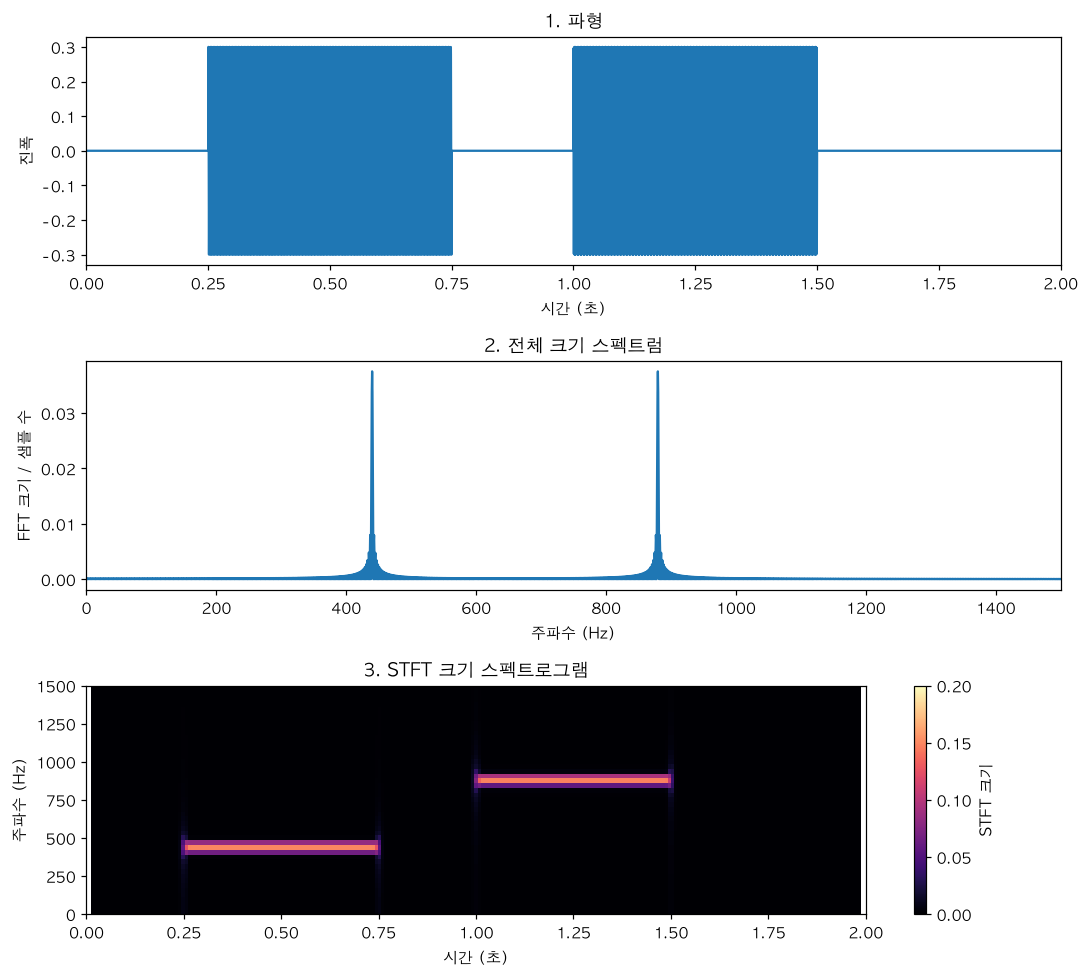

In [34]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))

axes[0].plot(time, audio)
axes[0].set(title="1. 파형", xlabel="시간 (초)", ylabel="진폭", xlim=(0, 2))

axes[1].plot(frequency_axis, fft_size)
axes[1].set(title="2. 전체 크기 스펙트럼", xlabel="주파수 (Hz)",
            ylabel="FFT 크기 / 샘플 수", xlim=(0, 1500))

mesh = axes[2].pcolormesh(frame_times, frequencies, magnitude,
                          shading="auto", cmap="magma", vmin=0, vmax=0.2)
axes[2].set(title="3. STFT 크기 스펙트로그램", xlabel="시간 (초)",
            ylabel="주파수 (Hz)", xlim=(0, 2), ylim=(0, 1500))
fig.colorbar(mesh, ax=axes[2], label="STFT 크기")

plt.tight_layout()

RESULT_DIR = Path("results")
RESULT_DIR.mkdir(exist_ok=True)
figure_path = RESULT_DIR / "lesson03_three_views.png"
fig.savefig(figure_path, dpi=140, bbox_inches="tight")
plt.show()

In [35]:
observation = {
    "lesson": 3,
    "example_id": "tone_sequence",
    "kind": "합성음: 실제 발화 아님",
    "file": sample_path.name,
    "sr": sr,
    "frame_length": 512,
    "hop_length": 128,
    "feature_shape_frequency_time": list(magnitude.shape),
    "figure": figure_path.name,
    "파형이_답하는_질문": "여기에 내 설명을 작성하세요.",
    "스펙트럼이_답하는_질문": "여기에 내 설명을 작성하세요.",
    "스펙트로그램에서_찾은_근거": "여기에 시간·주파수·색을 연결해 작성하세요."
}
output_path = RESULT_DIR / "lesson03_observation.json"
output_path.write_text(json.dumps(observation, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(observation, ensure_ascii=False, indent=2))

{
  "lesson": 3,
  "example_id": "tone_sequence",
  "kind": "합성음: 실제 발화 아님",
  "file": "tone_sequence_16k_mono.wav",
  "sr": 16000,
  "frame_length": 512,
  "hop_length": 128,
  "feature_shape_frequency_time": [
    257,
    247
  ],
  "figure": "lesson03_three_views.png",
  "파형이_답하는_질문": "여기에 내 설명을 작성하세요.",
  "스펙트럼이_답하는_질문": "여기에 내 설명을 작성하세요.",
  "스펙트로그램에서_찾은_근거": "여기에 시간·주파수·색을 연결해 작성하세요."
}


## 실제 음성 실습 — 내 목소리를 파형·FFT·STFT로 비교하기

앞에서는 **440Hz와 880Hz를 미리 알고 있는 합성음**으로 FFT와 STFT의 원리를 확인했습니다.  
이제 2강에서 사용한 " **my_voice.wav** "를 이용하여 실제 음성을 분석합니다.

실제 사람의 목소리는 하나의 주파수로 이루어져 있지 않습니다.  
시간에 따라 여러 주파수 성분의 크기가 계속 달라지므로 합성음보다 훨씬 복잡한 모양이 나타납니다.

이번 실습에서는 같은 음성을 세 가지 방법으로 살펴봅니다.

```text
실제 음성 my_voice.wav
        ↓
16kHz · 모노로 전처리
        ↓
 ┌────────────┬────────────┬────────────┐
 │   파형     │ 전체 FFT   │    STFT    │
 │ 언제 소리가 │ 어떤 주파수│  어떤 주파수│
 │ 있는가?    │ 가 있는가?  │  가 언제?  │
 └────────────┴────────────┴────────────┘
```

### 실습 목표

1. 실제 음성 파일의 **SR·채널·길이**를 확인합니다.
2. 스테레오 음성은 **모노**로 변환하고, 샘플링 레이트는 **16kHz로 실제 리샘플링**합니다.
3. 같은 음성을 **파형 → 전체 FFT → STFT** 순서로 비교합니다.
4. 합성음과 실제 음성의 차이를 설명합니다.

> **주의:** 샘플링 레이트 숫자만 16000으로 바꾸는 것은 리샘플링이 아닙니다.  
> `resample_poly()`를 사용하여 실제 샘플 데이터를 16kHz 기준으로 다시 계산합니다.

파일 위치는 `data/my_voice.wav` 또는 노트북과 같은 폴더의 `my_voice.wav`입니다.


### 1단계 — 실제 음성 읽기와 16kHz 모노 변환

먼저 파일을 읽고 원본의 샘플링 레이트와 채널 수를 확인합니다.  
스테레오이면 두 채널의 평균을 사용하여 모노로 만들고, `resample_poly()`로 16kHz로 변환합니다.

전처리 후에도 **음성의 재생 시간은 거의 같아야 합니다.**  
달라지는 것은 1초를 표현하는 샘플의 개수입니다.


In [36]:
from scipy.signal import resample_poly
from math import gcd

# data 폴더 또는 노트북 옆에서 my_voice.wav 찾기
voice_path = next(
    (p for p in [DATA_DIR / "my_voice.wav", Path("my_voice.wav")] if p.is_file()),
    None
)

if voice_path is None:
    raise FileNotFoundError(
        "2강의 my_voice.wav를 data 폴더 또는 노트북 옆에 놓으세요."
    )

# PCM16 WAV 읽기
voice_sr, voice_raw = read_pcm16(voice_path)

# 원본 채널 수 확인
channels = 1 if voice_raw.ndim == 1 else voice_raw.shape[1]

# 스테레오이면 두 채널의 평균으로 모노 변환
voice_mono = voice_raw if channels == 1 else voice_raw.mean(axis=1)

# 원본 SR → 16000Hz로 실제 리샘플링
common = gcd(voice_sr, 16000)
voice_16k = resample_poly(
    voice_mono,
    16000 // common,
    voice_sr // common
)

# 원본과 변환 결과 확인
print(f"원본: {voice_sr} Hz / {channels}채널 / {len(voice_mono)/voice_sr:.3f}초")
print(f"변환: 16000 Hz / 모노 / {len(voice_16k)}샘플 / {len(voice_16k)/16000:.3f}초")


원본: 44100 Hz / 2채널 / 7.960초
변환: 16000 Hz / 모노 / 127360샘플 / 7.960초


### 2단계 — 파형으로 ‘언제 소리가 있는가?’ 보기

파형은 **시간에 따라 음성의 진폭이 어떻게 변하는지** 보여 줍니다.  
따라서 말한 구간, 무음 구간, 소리가 커지거나 작아지는 구간을 관찰하기 좋습니다.

아래 그래프와 재생기는 **같은 `voice_16k` 데이터**를 사용합니다.


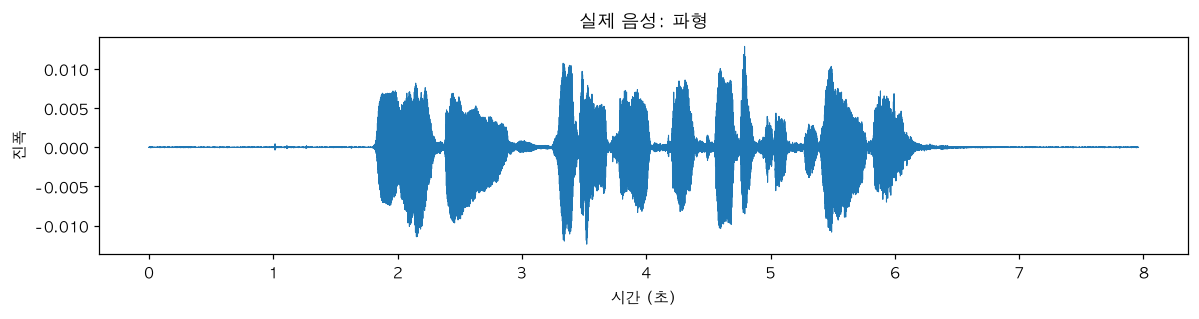

▶ 위 파형에 사용된 실제 음성


In [37]:
# 파형의 시간축 만들기
voice_time = np.arange(len(voice_16k)) / 16000

# 실제 음성 파형 그리기
plt.figure(figsize=(11, 3))
plt.plot(voice_time, voice_16k, linewidth=0.7)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("실제 음성: 파형")
plt.tight_layout()
plt.show()

# 위 파형에 사용된 실제 음성 듣기
print("▶ 위 파형에 사용된 실제 음성")
# display(Audio(voice_16k, rate=16000, normalize=False))


### 3단계 — 전체 FFT로 ‘어떤 주파수가 있는가?’ 보기

전체 음성을 한 번에 FFT하면 녹음 전체에 포함된 **주파수별 크기**를 볼 수 있습니다.  
하지만 해당 주파수가 **언제 나타났는지**는 알기 어렵습니다.

실제 음성에는 기본 주파수, 배음, 공명, 잡음 등 여러 성분이 함께 있으므로  
합성음처럼 한두 개의 뚜렷한 봉우리만 나타나지 않을 수 있습니다.


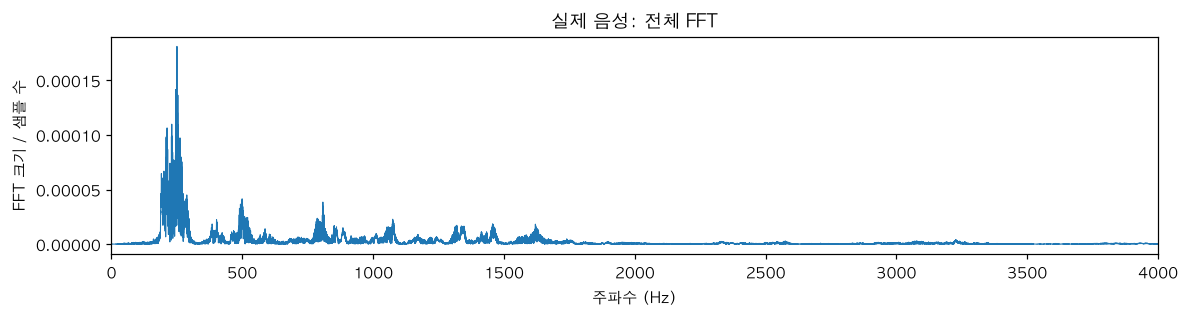

In [38]:
# FFT 결과의 주파수축 만들기
voice_freq = np.fft.rfftfreq(len(voice_16k), d=1 / 16000)

# 전체 음성을 FFT하고 주파수별 크기 계산
voice_fft = np.abs(np.fft.rfft(voice_16k)) / len(voice_16k)

# 수업에서 읽기 쉽도록 0~4000Hz 구간 표시
plt.figure(figsize=(11, 3))
plt.plot(voice_freq, voice_fft, linewidth=0.7)
plt.xlabel("주파수 (Hz)")
plt.ylabel("FFT 크기 / 샘플 수")
plt.title("실제 음성: 전체 FFT")
plt.xlim(0, 4000)
plt.tight_layout()
plt.show()


### 4단계 — STFT로 ‘어떤 주파수가 언제 나타나는가?’ 보기

STFT는 음성을 짧은 구간으로 나누고 각 구간마다 FFT를 수행합니다.  
그래서 **시간에 따라 주파수 성분이 어떻게 변하는지** 볼 수 있습니다.

```text
가로축 → 시간
세로축 → 주파수
색     → 해당 시간·주파수 성분의 크기
```

밝은 부분은 해당 시간에 그 주파수 성분이 상대적으로 강하다는 뜻입니다.  
가장 밝은 한 칸이 항상 기본 주파수나 특정 발음을 의미하는 것은 아닙니다.


STFT 표 (주파수, 시간): (257, 992)


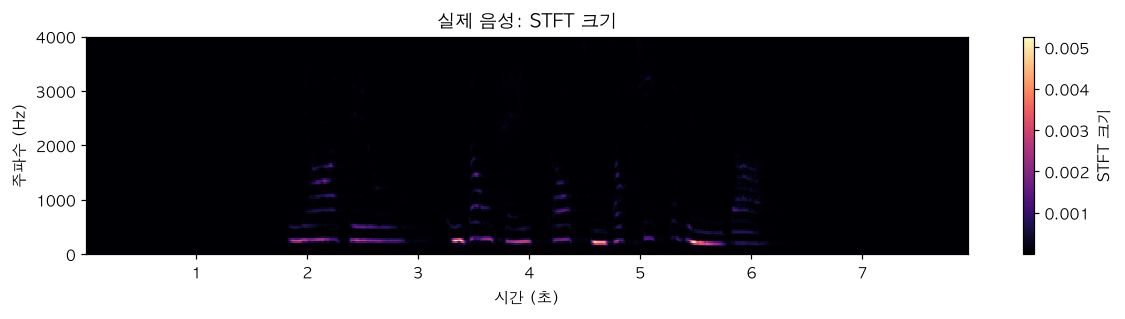

In [39]:

# ============================================================
# 실제 음성을 STFT로 분석하고 시간-주파수 그래프로 표시
# ============================================================

# voice_16k : 16,000Hz로 변환된 모노 음성의 1차원 배열
#             예) 2초 음성이라면 32,000개 샘플
#
# STFT는 음성을 짧은 구간으로 나누어 각 구간에 FFT를 수행합니다.
# 이를 통해 시간에 따라 주파수 성분이 어떻게 변하는지 분석합니다.


# ------------------------------------------------------------
# 1. STFT 수행
# ------------------------------------------------------------
# vf: 주파수별 Hz 값, vt: 분석 구간별 시간(초), vz: 시간·주파수별 STFT 복소수 분석 결과
vf, vt, vz = compute_stft(
    voice_16k,   # 분석할 음성 샘플 배열
    16000,       # 샘플링 레이트(SR): 1초에 16,000개 샘플
    512,         # 창 길이: 한 번에 512개 샘플 분석 (32ms)
    128          # 이동 간격: 128개 샘플씩 이동 (8ms)
)

# 분석 과정
# ① 첫 번째 512개 샘플을 가져와 FFT 수행
# ② 128개 샘플만큼 이동하여 다시 512개 샘플 분석
# ③ 음성 끝까지 반복하여 시간별 주파수 정보를 계산
#
# 창 길이 = 512 / 16000 = 0.032초 = 32ms
# 이동 간격 = 128 / 16000 = 0.008초 = 8ms
#
# 따라서 32ms 길이의 구간을 8ms마다 분석합니다.
# 인접한 분석 구간은 384개 샘플(24ms)이 겹칩니다.


# ------------------------------------------------------------
# 2. STFT 반환값의 의미
# ------------------------------------------------------------

# vf : 주파수 칸의 실제 주파수(Hz)를 저장한 1차원 배열
#      FFT 크기가 512이므로 주파수 칸은 257개입니다.
#
#      주파수 칸 수 = 512 / 2 + 1 = 257개
#      최대 주파수 = 16000 / 2 = 8000Hz
#      주파수 간격 = 16000 / 512 = 31.25Hz
#
#      vf의 값:
#      [0, 31.25, 62.5, 93.75, ..., 8000]
#
# vt : 각 STFT 분석 구간의 중심 시간(초)을 저장한 배열
#      예) 0.016, 0.024, 0.032, ... 초
#      분석 구간의 중심은 8ms 간격으로 이동합니다.
#
# vz : STFT 분석 결과를 저장한 2차원 복소수 배열
#      배열 모양: (주파수 칸 수, 시간 칸 수)
#
#      vz[10, 20]은
#      20번 시간 칸에서 10번 주파수 칸의 분석 결과입니다.
#      복소수에는 주파수 성분의 크기와 위상 정보가 포함됩니다.


# ------------------------------------------------------------
# 3. 복소수 STFT 결과에서 크기(Magnitude) 추출
# ------------------------------------------------------------

voice_mag = np.abs(vz)

# np.abs()는 복소수의 절댓값을 계산합니다.
# 즉, 각 시간·주파수 위치에서 성분이 얼마나 강한지 나타냅니다.
#
# STFT 원본 vz       : 복소수 배열 (크기와 위상 정보)
# STFT 크기 voice_mag: 실수 배열 (크기 정보만)
#
# 예를 들어 voice_mag[10, 20]은
# 20번 시간 구간에서 10번 주파수 성분의 크기입니다.
#
# 값이 클수록 해당 주파수 성분이 강하게 나타납니다.


# ------------------------------------------------------------
# 4. 분석 결과의 배열 크기 확인
# ------------------------------------------------------------

print("STFT 표 (주파수, 시간):", voice_mag.shape)

# 첫 번째 차원 : 주파수 칸 수
# 두 번째 차원 : 시간 칸 수
#
# 예) (257, 247)이라면
#     247개의 시간 구간을 분석했고,
#     각 시간 구간마다 257개의 주파수 크기 값이 있습니다.
#
# 실제 시간 칸 수는 음성 길이에 따라 달라집니다.


# ------------------------------------------------------------
# 5. STFT 결과를 시간-주파수 그래프로 표시
# ------------------------------------------------------------

plt.figure(figsize=(11, 3))

# pcolormesh()는 2차원 배열의 값을 색상으로 표현합니다.
mesh = plt.pcolormesh(
    vt,             # X축: 분석 구간의 중심 시간(초)
    vf,             # Y축: 각 주파수 칸의 실제 주파수(Hz)
    voice_mag,      # 색상: 해당 시간·주파수 성분의 크기
    cmap="magma",   # 작은 값은 어둡게, 큰 값은 밝게 표시
    shading="auto"  # 데이터 크기에 맞게 색상 영역 처리
)

# 그래프의 X축과 Y축 이름
plt.xlabel("시간 (초)")
plt.ylabel("주파수 (Hz)")

# 그래프 제목
plt.title("실제 음성: STFT 크기")

# Y축 표시 범위를 0~4000Hz로 제한합니다.
# 실제 STFT는 0~8000Hz까지 계산되어 있습니다.

# 여기서는 음성의 주요 저주파 영역을 보기 위해
# 그래프에 표시하는 범위만 제한합니다.
# 데이터 자체를 삭제하거나 다시 계산하지는 않습니다.
plt.ylim(0, 4000)

# 오른쪽에 색상 막대를 표시합니다.
# 어두운 색 : 해당 주파수 성분의 크기가 작음
# 밝은 색   : 해당 주파수 성분의 크기가 큼
plt.colorbar(mesh, label="STFT 크기")

# 그래프 요소가 겹치지 않도록 배치합니다.
plt.tight_layout()

# 최종 그래프 출력
plt.show()


### 5단계 — 세 그림을 비교하여 해석하기

같은 음성을 서로 다른 관점으로 본 결과입니다.

| 표현 | 주로 답할 수 있는 질문 | 한계 |
|---|---|---|
| 파형 | 소리가 **언제** 나타나고 크기가 어떻게 변하는가? | 어떤 주파수인지 바로 알기 어려움 |
| 전체 FFT | 녹음 전체에 **어떤 주파수**가 포함되어 있는가? | 그 주파수가 언제 나타났는지 알기 어려움 |
| STFT | **어떤 주파수가 언제** 강하게 나타나는가? | FFT보다 결과가 복잡하고 설정에 따라 모양이 달라짐 |

> **핵심:** 실제 음성은 시간에 따라 주파수 성분이 계속 변하므로,  
> 전체 FFT보다 STFT가 음성의 시간적 변화를 관찰하는 데 더 적합합니다.

#### 내 관찰

- 원본 SR·채널·길이: ___
- 16kHz 변환 후 샘플 수·길이: ___
- 파형에서 발화가 보이는 대략적인 시간: ___
- 전체 FFT에서 눈에 띄는 주파수 범위: ___
- STFT에서 밝은 영역이 시간에 따라 어떻게 변하는가: ___
- 합성음과 실제 음성 그림의 차이: ___


### 6단계 — 결과 그림과 관찰 기록 저장

아래 셀은 수업 결과를 파일로 남기기 위한 코드입니다.  
세 그래프를 하나의 PNG로 저장하고, 관찰 내용은 JSON 파일로 저장합니다.

`voice_reason`, `voice_stft_note`의 **‘미작성’ 문장을 자신의 관찰 내용으로 바꾼 뒤 실행**하세요.


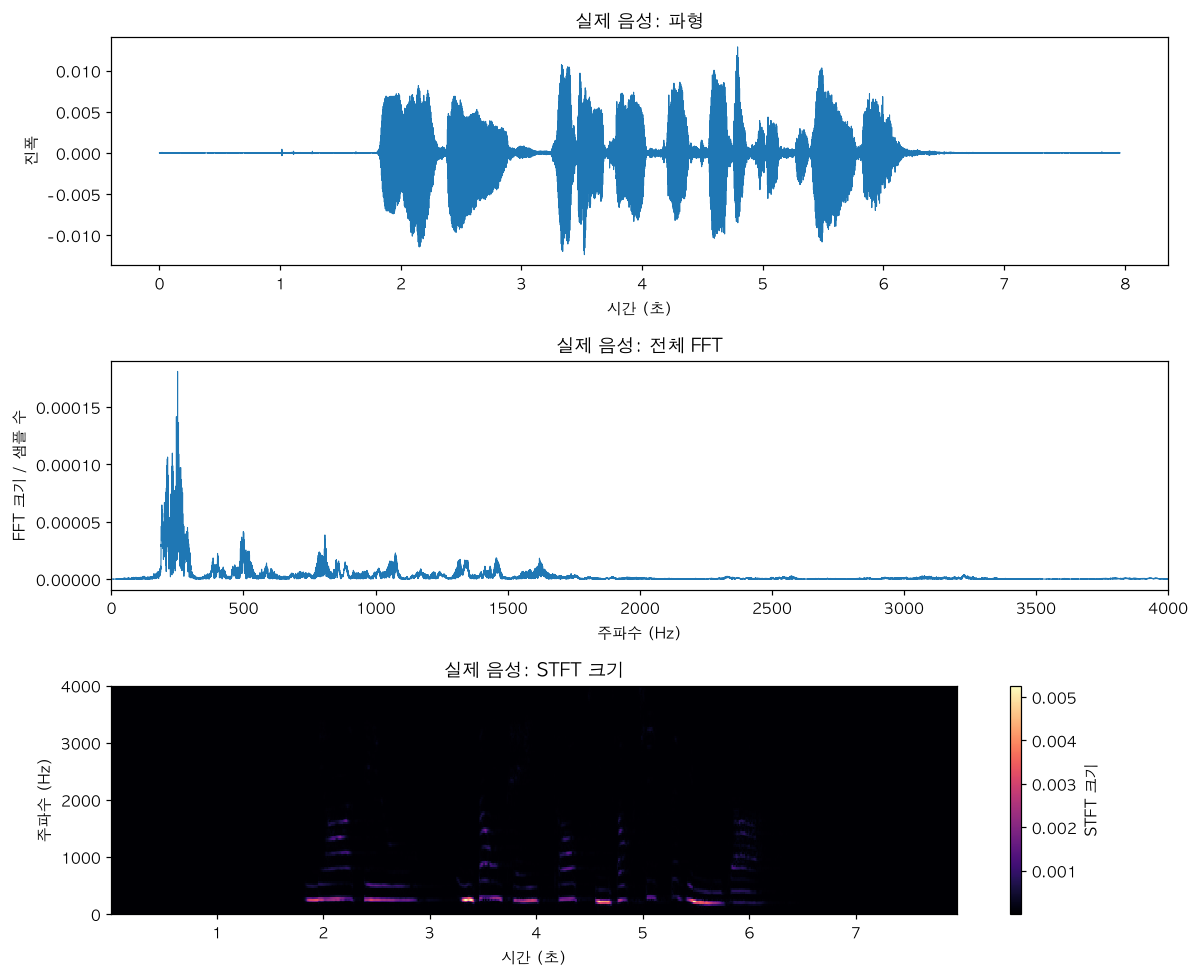

그림 저장: results/lesson03_my_voice_three_views.png
기록 저장: results/lesson03_my_voice_observation.json
{
  "source_file": "my_voice.wav",
  "original_sr": 44100,
  "original_channels": 2,
  "original_duration_seconds": 7.96,
  "processed_sr": 16000,
  "processed_duration_seconds": 7.96,
  "frame_length": 512,
  "hop_length": 128,
  "stft_shape_frequency_time": [
    257,
    992
  ],
  "figure": "lesson03_my_voice_three_views.png",
  "관찰_파형과_FFT": "미작성: 파형과 전체 FFT로 알 수 있는 것과 한계를 적으세요.",
  "관찰_STFT": "미작성: STFT에서 시간·주파수·색을 연결해 관찰 내용을 적으세요."
}


In [40]:
# 결과 저장 폴더 준비
RESULT_DIR = Path("results")
RESULT_DIR.mkdir(exist_ok=True)

# 세 그림을 하나의 파일로 저장
fig, axes = plt.subplots(3, 1, figsize=(11, 9))

# 1. 파형
axes[0].plot(voice_time, voice_16k, linewidth=0.7)
axes[0].set(
    xlabel="시간 (초)",
    ylabel="진폭",
    title="실제 음성: 파형"
)

# 2. 전체 FFT
axes[1].plot(voice_freq, voice_fft, linewidth=0.7)
axes[1].set(
    xlabel="주파수 (Hz)",
    ylabel="FFT 크기 / 샘플 수",
    title="실제 음성: 전체 FFT",
    xlim=(0, 4000)
)

# 3. STFT
mesh = axes[2].pcolormesh(
    vt, vf, voice_mag,
    cmap="magma",
    shading="auto"
)
axes[2].set(
    xlabel="시간 (초)",
    ylabel="주파수 (Hz)",
    title="실제 음성: STFT 크기",
    ylim=(0, 4000)
)
fig.colorbar(mesh, ax=axes[2], label="STFT 크기")

plt.tight_layout()

# PNG 저장
voice_figure_path = RESULT_DIR / "lesson03_my_voice_three_views.png"
fig.savefig(voice_figure_path, dpi=140, bbox_inches="tight")
plt.show()

print("그림 저장:", voice_figure_path)

# 아래 두 문장을 자신의 관찰 내용으로 수정
voice_reason = "미작성: 파형과 전체 FFT로 알 수 있는 것과 한계를 적으세요."
voice_stft_note = "미작성: STFT에서 시간·주파수·색을 연결해 관찰 내용을 적으세요."

# 관찰 기록 만들기
voice_record = {
    "source_file": voice_path.name,
    "original_sr": voice_sr,
    "original_channels": channels,
    "original_duration_seconds": round(len(voice_mono) / voice_sr, 4),
    "processed_sr": 16000,
    "processed_duration_seconds": round(len(voice_16k) / 16000, 4),
    "frame_length": 512,
    "hop_length": 128,
    "stft_shape_frequency_time": list(voice_mag.shape),
    "figure": voice_figure_path.name,
    "관찰_파형과_FFT": voice_reason,
    "관찰_STFT": voice_stft_note
}

# JSON 파일로 저장
record_path = RESULT_DIR / "lesson03_my_voice_observation.json"
record_path.write_text(
    json.dumps(voice_record, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("기록 저장:", record_path)
print(json.dumps(voice_record, ensure_ascii=False, indent=2))


### 실제 음성 실습 정리

```text
my_voice.wav
     ↓
PCM16 읽기
     ↓
모노 변환
     ↓
16kHz 리샘플링
     ↓
파형 ──→ 언제 소리가 있는가?
     ↓
전체 FFT ──→ 어떤 주파수가 있는가?
     ↓
STFT ──→ 어떤 주파수가 언제 나타나는가?
     ↓
관찰 내용 기록
```

**합성음 실습**에서는 정답이 440Hz·880Hz라는 것을 알고 FFT와 STFT가 제대로 찾는지 확인했습니다.  
**실제 음성 실습**에서는 정답 주파수 하나를 찾는 것이 목적이 아니라, 실제 목소리가 여러 주파수 성분으로 이루어지고 그 성분이 시간에 따라 변한다는 것을 확인하는 것이 목적입니다.

> **완료 기준:** 파형·전체 FFT·STFT가 각각 무엇을 보여 주는지 구분하고, 실제 음성에서 관찰한 내용을 시간과 주파수를 사용하여 설명할 수 있으면 됩니다.


**완료 기준:** 세 그림의 축을 구분하고, 시간과 주파수를 포함한 관찰 근거를 적습니다.
FFT 수식을 설명하거나 STFT 함수를 직접 구현할 필요는 없습니다.

## 나가기 문제 · 10분

1. 어떤 주파수가 **언제** 나타났는지 보려면 세 그림 중 무엇을 고르나요?
2. 스펙트로그램에서 주파수가 높은 위치와 밝은 색은 같은 뜻인가요?
3. 16000 Hz에서 512샘플 창은 몇 ms인가요?
4. 창을 고정하고 이동 간격만 줄이면 음성 파일의 길이도 바뀌나요?
5. 스펙트로그램 그림을 얻었으면 모델 입력 준비가 언제나 끝난 것인가요?

<details><summary>예시 답안</summary>

1. 시간과 주파수 축을 함께 가진 스펙트로그램입니다.
2. 아닙니다. 세로 위치는 주파수, 색은 해당 칸의 크기입니다.
3. 512÷16000×1000=32ms입니다.
4. 음성 길이와 창 폭은 그대로이며, 관찰하는 시간 칸이 늘어납니다.
5. 아닙니다. 모델에 맞는 특징 종류·SR·축·길이 등 입력 조건을 추가로 확인해야 합니다.

</details>

## 다음 강의와 참고

4강에서는 많은 주파수 칸을 목적에 맞게 묶은 **Mel 특징**을 배웁니다.
오늘의 세 축, 즉 시간·주파수·크기를 이해했다면 다음 단계로 넘어갈 준비가 된 것입니다.

<details><summary>참고 자료</summary>

- 원 자료 연결: W4D3_FFT_STFT. DFT 직접 구현·역변환·위상 복원·누설의 상세 증명은 필수에서 덜어냈습니다.
- [SciPy STFT 계산 조건](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.stft.html)
- 수업에서는 짧은 함수 호출로 설정을 설명하기 위해 `scipy.signal.stft`를 사용합니다. SciPy는 이 함수를 legacy로 분류하며 새 개발에는 `ShortTimeFFT`를 안내합니다. 이번 배포의 실행 검증 환경은 별도 파일에 기록했습니다.

</details>